# Case Study 5 — "Delivered By Friday": Promise Dates with Quantile Regression, Breach Control and Conformal Coverage

**Priority:** ★★ Good to have · **Reference:** Case Study 5 — *Myntra: customer promise date with breach control* (`indian_ecommerce_data_science_case_studies.md`)
**Audience:** Head of Supply Chain / Logistics, Product (checkout and product page), Customer Experience, Finance
**Data:** ⚠️ **SYNTHETIC** (D-5-01). Myntra's order and logistics data are confidential. This is a simulation with hidden realised processing and shipping times.
**Evidence level of the reference:** Strong for the problem and the approach (a workshop paper by Myntra authors that says the solution is deployed), but business impact beyond accuracy is not documented. This notebook is an interview-standard solution on simulated data, not a reproduction of Myntra's system.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs05_delivery_promise_date.ipynb`

## 0. Executive Summary for Business

*(Synthetic orders with hidden processing and shipping times, built on the documented design of Myntra's promise-date work: promise = warehouse time + shipping time, quantile regression for breach control, sale-day (HRD) models, and a rule-based baseline. Myntra's data and results are not reproduced and public method detail is thin; this is an interview-standard solution on simulated data. Written after the analysis.)*

- **The question:** which delivery date should checkout show so that late deliveries (breaches) stay at or below **5%**, with as little padding as possible, including on sale days?
- **A learned 95th-percentile model is far tighter than the rule-based table, with fewer breaches.** On normal (BAU) test days the rule-based zone table promises **5.97 days on average and is accurate (on the promised date or one day early) for only 16.6% of orders**, with 2.0% breach. Quantile regression promises 5.29 days with **1.3% breach** and 37.4% accuracy; its pinball loss is the lowest of the four candidates compared (0.149 vs 0.195 for the table, day-bootstrap CI of the gap 0.040 to 0.058).
- **But plain quantile regression is too cautious: 1.3% breach against a 5% target.** Promises are rounded up to whole days, which adds slack. **Split-conformal calibration** fixes this: BAU breach **4.9%** (day-bootstrap CI 3.8% to 5.9%, so we cannot reject 5%) with accuracy **73.7%** and a mean promise of 4.28 days.
- **The conformal guarantee behaves as theory says on exchangeable data.** Over 400 random calibration sets, mean coverage was 94.9% to 95.0% for n = 100, 500 and 2,000, matching the Beta law (KS p between 0.34 and 0.69).
- **It does not hold on sale days.** The same offset gives **9.6% breach on sale days and 11.8% after the sale** (coverage 90.4% and 88.2%). Mondrian per-zone calibration (BAU 4.9%, sale 10.1%) and 10-day rolling conformal (BAU 6.9%) do not repair this, because recent feedback is mostly unavailable: only **6.6%** of the last three days of orders have been delivered. A 3-day feedback correction is far worse (34% breach).
- **Segments are not equal under one offset.** Split-conformal breach on BAU days runs from 3.9% (remote) to 5.3% (tier-2) by zone, and is 6.0% for orders after the 16:00 cut-off versus 3.9% before; zone and cut-off differences remain significant after Holm correction (p = 0.008 and below 1e-4).
- **Recommended rule (added after seeing the result, so it needs a live check):** use the conformal offset on normal days and plain quantile regression on sale and post-sale days. On the test days this gives **4.9% BAU breach, 4.6% on sale days and 4.3% after**, against 6.8% and 6.4% for the rule-based table on sale and post-sale days, with a mean promise 0.21 days shorter than the table on those days.
- **Money (assumed elasticities):** versus the rule-based table on BAU days, split-conformal is worth about **₹15.8 crore a year in the base case** (worst case ₹-1.4 crore, best ₹42.3 crore), because the promise is 1.69 days shorter. Plain quantile regression is worth ₹19.3 crore in the base case with a smaller downside (₹7.4 crore worst).
- **Verification needs volume:** certifying 5% within 1 percentage point needs about **1,825 orders (4,034 with day clustering)**; no lane reaches that in a week (median 14 orders per lane), so certify by zone, not by lane.
- **I recommend:** ship quantile regression with a conformal offset on normal days, plain quantile regression on sale days, report breach by zone and cut-off daily, and confirm in a live test on the next sale.

## 1. The Problem in Simple English

When you place an order the app says **"Delivery by Friday"**. That date is a promise. Two mistakes are possible, and they cost different amounts:
- **Promise too late** (say Sunday when it would arrive Thursday): some customers do not buy at all. You lose the sale.
- **Promise too early** (Wednesday, and it arrives Friday): the customer is unhappy, contacts support and may not come back. This is a **breach**.

So the promise date is not "our best guess of the delivery date". It is a **safe date**: late enough that only a small share of orders (say 5%) arrive after it, but not later than needed. In statistics that is a **quantile** (the 95th percentile of delivery time), not an average.

Leaders and interviewers want to know:
1. How much better is a learned promise than the **rule-based** table of fixed days per region?
2. Why not simply predict the **average** and add a day? Why not use an **asymmetric loss**?
3. Can we **guarantee** that breaches stay below 5%, and for which customers does the guarantee fail (remote areas, 3PL couriers, **sale days**)?
4. What happens on **high revenue days** (big sales), when delivery gets slower and less predictable?
5. What is a tighter promise worth in ₹, and what does a breach cost?

## 2. Reference from the Case File

### (a) What Myntra did — *documented*

| Item | Documented fact (from the reference file) |
|---|---|
| Problem | Predict the customer promise date at order placement. A date later than actual delivery "might sometimes result in the customer not placing the order"; earlier than actual "would lead to a bad customer experience and consequent customer churn". Indian constraints: remote areas, traffic, weather, regional holidays, hard-to-read addresses, low SKU depth in fashion, and high revenue days (HRD) with more variability |
| Baseline | A rule-based model with configured static processing times per supply-chain leg |
| Approach | Promise date = order time + warehouse (or vendor-procurement) time + shipping time. Warehouse leg: time series (fbprophet) and gradient boosting. Shipping leg: LightGBM with lane and last-mile-centre features, recency-weighted examples, holiday and weekend handling. Dedicated HRD models trained on proxy days from a prior sale event |
| Breach control | Three routes were compared: asymmetric loss functions, **quantile regression**, and a feedback-based breach control model that corrects the model using recent prediction errors |
| Metrics | Accuracy (0 to -1) = share delivered on the promised date or one day earlier; Breach = share delivered after the promised date |
| Reported results (authors' own) | BAU days: quantile regression accuracy 68.1% and breach 4.68% vs rule-based 36.6% and 5.63%. The paper says asymmetric loss could not control breaches deterministically. On HRD the gradient-boosting model raised accuracy but breach rates were *higher* than the baseline's (7.86% vs 5.44%) |
| Not documented | Revenue, conversion or return impact |

**Source:** Preethi V, Nachiappan Sundaram, Ravindra Babu Tallamraju, "Online Fashion Commerce: Modelling Customer Promise Date", arXiv:2105.00315 (2021), SDM Data Science for Retail and E-Commerce Workshop. The Flipkart-group link is background knowledge, not stated in the pages read.

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | 60 days, about 140,000 orders, 6 warehouses and 60 last-mile centres in three zones, own fleet and 3PL couriers, vendor-procured items, a 16:00 cut-off, Sunday and regional holidays, hidden daily backlogs, and two sale events (3 days each) |
| Target | Delivery day offset D = delivery date minus order date (whole days) |
| Methods compared | (1) Rule-based zone table; (2) mean model plus one day; (3) asymmetric (expectile) loss; (4) **quantile regression** at 0.95; (5) feedback breach control; (6) **split-conformal** offset; (7) Mondrian (per-zone) conformal; (8) rolling conformal with delayed outcomes; (9) a hybrid added after the sale-day result |
| Statistics added | Exact and cluster-bootstrap tests of the 5% breach target, McNemar on paired breaches, **finite-sample conformal coverage** checked by repeated splits against the Beta law, segment coverage heterogeneity tests (Holm), drift tests on sale days, an accuracy-vs-breach frontier, a linear quantile regression for interpretation, and sample size to certify a breach rate |
| What we do not copy | The paper's fbprophet and LSTM comparisons, and its LightGBM (we use scikit-learn gradient boosting; no tuning) |

### (c) How the industry uses this

Every Indian marketplace shows a promise date at checkout and the product page (Amazon, Flipkart, Myntra, Meesho, Ajio). Food and quick commerce show a time (Case 1). The promise is usually a high quantile of a learned delivery-time distribution, with rules on top for cut-offs, holidays and sale events, and a monitoring layer on breach rate by region and courier. Quantile regression and conformal prediction are common interview topics because they turn "hit a service level" into a testable statement.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | Which date should we show at checkout so that late deliveries stay under the business limit, with as little padding as possible? |
| Analytical | Which promise rule keeps the breach rate at or below 5% on normal days, for every customer segment and on sale days, with the highest accuracy (delivered on the promised date or one day earlier)? |

**Hypotheses** (target breach rate α = 5%)
- **H1:** H0: the breach rate of each method on normal (BAU) days is at most 5% (exact binomial, plus a day-level cluster bootstrap because orders on a day share backlogs).
- **H2:** H0: quantile regression and the rule-based table have equal breach and accuracy on the same orders (McNemar; Holm).
- **H3 (conformal guarantee):** H0: conformal coverage on exchangeable data follows the theoretical Beta law, with mean ⌈(n+1)(1−α)⌉ / (n+1) (repeated random splits).
- **H4 (segments):** H0: breach rate is the same across zones, couriers, vendor items, cut-off timing and period (chi-square; Holm across 12 tests).
- **H5 (drift):** H0: model residuals on sale days have the same distribution as on the calibration days (KS test).

**Primary metrics:** **breach** (share delivered after the promised date) and **accuracy (0 to −1)** (on the promised date or one day earlier; (0 to −2) on HRD). **Diagnostics:** mean promised days, mean slack (days of padding), pinball loss at 0.95.

In [1]:
import sys, warnings, importlib, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.ensemble import HistGradientBoostingRegressor
from threadpoolctl import threadpool_limits
threadpool_limits(1)
from sklearn.inspection import permutation_importance
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public Indian ecommerce delivery data | **None usable.** Public logistics sets (for example Brazilian Olist orders, or US carrier data) have different networks and no hidden truth, and none has Indian pincode lanes, 3PL partners or sale-day effects. Myntra's paper publishes only aggregate results |
| **Decision** | Synthetic orders calibrated to the documented structure (legs, pendency, 3PL, holidays, HRD) so that coverage and breach can be checked against a known setting (D-5-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs05.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 5 (Myntra-style customer promise date with breach control)
================================================================================================
THIS DATA IS SYNTHETIC. Myntra order and logistics data are confidential.

Documented context (Preethi, Sundaram, Tallamraju, arXiv:2105.00315, 2021): promise date = order time + warehouse
(or vendor-procurement) time + shipping time; shipping through hubs to a last-mile centre; 3PL courier partners with
limited visibility; pendency at linehaul and last-mile centres; regional holiday calendars; high revenue days (HRD)
with higher variability and cut-offs not adhered to; a rule-based model with static configured times as the baseline;
breach (delivered after the promised date) to be kept below a business limit; training on recent weeks, test on the
next order day. The paper's BAU levels (baseline accuracy 36.6% / breach 5.6%) are only used as an order of magnitude.

Simulation: ~60 days, ~2,000 orders/day on business-as-usual (BAU) days, ~2.6x on sale days (HRD).
  * 6 warehouses, 60 last-mile centres in three zones (metro, tier-2, remote), lane = (warehouse, centre).
  * Warehouse backlog and centre backlog are hidden AR(1) processes; the model sees only yesterday's noisy reading.
  * Orders: 1-6 items, 12% contain a vendor-procured item (long wait), cut-off at 16:00, 3PL for remote zones mostly.
  * Shipping: distance-based linehaul with hub handling, last-mile time by zone, weekend/holiday deferral,
    3PL stalls (heavy tail), and HRD pressure (higher mean AND higher variance).
  * Target: delivery day offset D = delivery calendar date minus order calendar date (integer days).
Hidden truth (prefix _): realised processing hours, shipping hours, stall flag, true backlogs.

Outputs: data/cs05/orders.csv.gz, data/cs05/centres.csv.gz
"""
import os
import numpy as np
import pandas as pd

SEED = 42
START = pd.Timestamp("2026-08-03")  # a Monday
DAYS = 60
N_WH, N_C = 6, 60
HRD_DAYS = (14, 15, 16, 46, 47, 48)      # prior sale event (usable as proxy) and the test-period sale event
POST_HRD = (17, 49, 50)
NATIONAL_HOLIDAYS = (12, 29)             # days (Aug 15 falls on day 12; day 29 is an illustrative festival)


def generate(seed=SEED):
    rng = np.random.default_rng(seed)
    # --- network ---------------------------------------------------------------------------------------------
    wh_xy = np.array([[19.2, 72.9], [12.9, 77.6], [28.4, 77.0], [22.6, 88.4], [17.4, 78.5], [13.1, 80.3]])
    wh_xy = wh_xy + rng.normal(0, 0.05, wh_xy.shape)
    zone = rng.choice(["metro", "tier2", "remote"], N_C, p=[0.30, 0.45, 0.25])
    c_xy = np.column_stack([rng.uniform(9, 31, N_C), rng.uniform(70, 92, N_C)])
    centres = pd.DataFrame({"centre": np.arange(N_C), "zone": zone, "lat": c_xy[:, 0].round(2), "lon": c_xy[:, 1].round(2)})
    dist = np.sqrt(((c_xy[:, None, :] - wh_xy[None, :, :]) ** 2).sum(2)) * 111 * 1.25     # km, road factor (N_C, N_WH)
    # nearest warehouse is the usual source (fashion has low SKU depth, so 35% are shipped from another one)
    near = dist.argmin(1)
    w_share = rng.dirichlet(np.ones(N_WH) * 4)
    # --- daily backlog processes ----------------------------------------------------------------------------
    hrd = np.zeros(DAYS, bool); hrd[list(HRD_DAYS)] = True
    post = np.zeros(DAYS, bool); post[list(POST_HRD)] = True
    hol = np.zeros(DAYS, bool); hol[list(NATIONAL_HOLIDAYS)] = True
    wh_bl = np.zeros((DAYS, N_WH)); c_bl = np.zeros((DAYS, N_C))
    for d in range(DAYS):
        prev_w = wh_bl[d - 1] if d else np.zeros(N_WH); prev_c = c_bl[d - 1] if d else np.zeros(N_C)
        shock_w = 1.1 * hrd[d] + 0.5 * post[d]; shock_c = 0.8 * hrd[d] + 0.7 * post[d]
        wh_bl[d] = 0.65 * prev_w + rng.normal(0, 0.35, N_WH) + shock_w
        c_bl[d] = 0.60 * prev_c + rng.normal(0, 0.45, N_C) + shock_c + (zone == "remote") * 0.25
    # centre-level regional holidays (known calendar)
    c_hol = rng.random((DAYS, N_C)) < 0.03
    # --- orders ----------------------------------------------------------------------------------------------
    n_day = np.where(hrd, rng.poisson(5200, DAYS), rng.poisson(2000, DAYS))
    n_day = np.where(post, rng.poisson(2800, DAYS), n_day)
    day = np.repeat(np.arange(DAYS), n_day); n = len(day)
    c_pop = rng.dirichlet(np.ones(N_C) * 1.5)
    centre = rng.choice(N_C, n, p=c_pop)
    own = near[centre]
    other = rng.random(n) < 0.35
    wh = np.where(other, rng.choice(N_WH, n, p=w_share), own)
    km = dist[centre, wh]
    z = zone[centre]
    n_items = np.minimum(6, 1 + rng.geometric(0.55, n) - 1 + (rng.random(n) < 0.15))
    n_items = np.maximum(1, n_items)
    vendor = rng.random(n) < (0.10 + 0.04 * hrd[day])
    hour = np.minimum(23.99, np.maximum(0, rng.normal(15.5, 5.0, n))); hour = np.where(rng.random(n) < 0.04, rng.uniform(0, 24, n), hour)
    hour = np.clip(hour, 0, 23.99)
    wd = (START.dayofweek + day) % 7   # 0 Mon ... 6 Sun
    p3pl = np.where(z == "remote", 0.75, np.where(z == "tier2", 0.30, 0.08))
    third = rng.random(n) < p3pl
    # -- hidden state for each order
    bw = wh_bl[day, wh]; bc = c_bl[day, centre]
    pressure = hrd[day] * 1.0 + post[day] * 0.5
    # warehouse processing hours
    cutoff_miss = hour >= 16
    wait_cut = np.where(cutoff_miss, (24 - hour) + 8.0, 0.0)
    # on HRD cut-offs are not adhered to: some pre-cutoff orders also slip
    slip = (hrd[day] & (hour >= 13) & (hour < 16) & (rng.random(n) < 0.35))
    wait_cut = wait_cut + np.where(slip, (24 - hour) + 8.0, 0.0)
    proc = np.exp(rng.normal(np.log(7.0) + 0.14 * bw + 0.07 * (n_items > 1) + 0.04 * (n_items > 3), 0.30 + 0.12 * pressure, n))
    proc = proc + np.where(vendor, rng.gamma(2.0, 20.0, n), 0.0) + wait_cut
    # shipping hours
    hops = 1 + np.ceil(km / 700.0)
    linehaul = km / 60.0 + 6.0 * hops
    lastmile = np.where(z == "metro", 7.0, np.where(z == "tier2", 13.0, 26.0))
    ship = linehaul + lastmile + np.exp(rng.normal(np.log(3.0) + 0.55 * bc, 0.45 + 0.18 * pressure, n)) * (1 + 0.6 * pressure)
    stall = rng.random(n) < (0.015 + 0.035 * third + 0.03 * (z == "remote") + 0.04 * pressure)
    ship = ship + np.where(stall, rng.gamma(2.5, 22.0, n), 0.0) + np.where(third, rng.gamma(2.0, 4.0, n), 0.0)
    # delivery timestamp with weekday/holiday deferral; deliveries only 09:00-21:00
    start = day * 24.0 + hour
    t = start + proc + ship
    for _ in range(3):
        dd = np.floor(t / 24).astype(int); hh = t - dd * 24
        wdd = (START.dayofweek + dd) % 7
        dd_c = np.minimum(dd, DAYS - 1)
        blocked = (wdd == 6) | np.isin(dd, NATIONAL_HOLIDAYS) | (c_hol[dd_c, centre] & (dd < DAYS))
        t = np.where(blocked, (dd + 1) * 24.0 + 10.0, t)
        late = (hh >= 21) & ~blocked
        t = np.where(late, (dd + 1) * 24.0 + 10.0, t)
        early = (hh < 9) & ~blocked
        t = np.where(early, dd * 24.0 + 10.0, t)
    D = np.floor(t / 24).astype(int) - day
    # --- observed features -------------------------------------------------------------------------------------
    prev_w = np.where(day[:, None] > 0, wh_bl[np.maximum(day - 1, 0)], 0)[np.arange(n), wh]
    prev_c = np.where(day > 0, c_bl[np.maximum(day - 1, 0), centre], 0.0)
    orders = pd.DataFrame({
        "order_id": np.arange(n), "order_ts": START + pd.to_timedelta(day * 86400 + (hour * 3600).astype(int), unit="s"),
        "day": day, "hour": hour.round(2), "weekday": wd, "is_national_holiday": hol[day].astype(int),
        "is_hrd": hrd[day].astype(int), "is_post_hrd": post[day].astype(int),
        "warehouse": wh, "centre": centre, "zone": z, "distance_km": km.round(0), "n_items": n_items,
        "vendor_item": vendor.astype(int), "carrier_3pl": third.astype(int),
        "pend_wh_prev_day": (prev_w + rng.normal(0, 0.15, n)).round(3), "pend_centre_prev_day": (prev_c + rng.normal(0, 0.15, n)).round(3),
        "centre_holiday_next2": 0,
        "planned_volume_ratio": np.where(hrd[day], rng.normal(2.6, 0.2, n), np.where(post[day], 1.4, 1.0)).round(2),
        "delivery_days": D, "delivery_ts": START + pd.to_timedelta((t * 3600).astype(np.int64), unit="s"),
        "_proc_hours": proc.round(1), "_ship_hours": ship.round(1), "_stall": stall.astype(int),
        "_wh_backlog": bw.round(3), "_centre_backlog": bc.round(3),
    })
    # centre regional holiday known for the next two days after the order
    h2 = np.zeros(n, int)
    for k in (1, 2):
        dk = np.minimum(day + k, DAYS - 1); h2 |= c_hol[dk, centre].astype(int)
    orders["centre_holiday_next2"] = h2
    # defects: delivered orders after the data cut-off are unobserved (right-censoring) and a few bad timestamps
    orders = orders.drop(columns=[])
    bad = rng.choice(n, 150, replace=False); orders.loc[bad, "delivery_days"] = np.nan
    dupl = orders.sample(n=400, random_state=seed)
    orders = pd.concat([orders, dupl], ignore_index=True)
    wr = rng.choice(len(orders), 60, replace=False); orders.loc[wr, "distance_km"] = orders.loc[wr, "distance_km"] * 100   # unit error
    return orders, centres


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs05"), exist_ok=True)
    o, c = generate(); o.to_csv(os.path.join(here, "cs05", "orders.csv.gz"), index=False); c.to_csv(os.path.join(here, "cs05", "centres.csv.gz"), index=False)
    print(len(o), o.delivery_days.describe().round(2).to_dict())

Overwriting data/generate_cs05.py


In [3]:
os.makedirs("data/cs05", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs05 as gen; importlib.reload(gen)
t0 = time.time(); raw, centres = gen.generate(seed=SEED); raw.to_csv("data/cs05/orders.csv.gz", index=False); centres.to_csv("data/cs05/centres.csv.gz", index=False)
print(f"{len(raw):,} order rows | {raw.order_id.nunique():,} unique orders | {raw.day.nunique()} days | generated in {time.time() - t0:.0f}s")
raw.drop(columns=[c for c in raw.columns if c.startswith("_")]).head(4)

142,374 order rows | 141,974 unique orders | 60 days | generated in 33s


,order_id,order_ts,day,hour,weekday,is_national_holiday,is_hrd,is_post_hrd,warehouse,centre,zone,distance_km,n_items,vendor_item,carrier_3pl,pend_wh_prev_day,pend_centre_prev_day,centre_holiday_next2,planned_volume_ratio,delivery_days,delivery_ts
0,0,2026-08-03 15:58:45,0,15.9800,0,0,0,0,3,45,tier2,569.0000,1,0,0,0.1380,-0.0260,0,1.0000,2.0000,2026-08-05 11:17:12
1,1,2026-08-03 15:45:27,0,15.7600,0,0,0,0,0,53,tier2,"1,627.0000",2,0,1,-0.1140,-0.1360,0,1.0000,3.0000,2026-08-06 18:23:46
2,2,2026-08-03 02:59:20,0,2.9900,0,0,0,0,5,42,tier2,933.0000,1,0,1,-0.0900,0.1680,0,1.0000,2.0000,2026-08-05 17:17:34
3,3,2026-08-03 21:50:43,0,21.8500,0,0,0,0,2,43,remote,828.0000,1,0,0,0.0500,-0.0980,0,1.0000,4.0000,2026-08-07 10:00:00


| Parameter | Value | Basis |
|---|---|---|
| Scale | 60 days, ≈ 2,000 orders a day on normal days, ≈ 5,200 on sale days | Our assumption (the paper says more than a million training examples over a few weeks) |
| Network | 6 warehouses, 60 last-mile centres (30% metro, 45% tier-2, 25% remote), lanes = warehouse × centre | **Documented** structure (legs, hubs, last-mile centres); sizes are ours |
| Couriers | 3PL share 8% metro, 30% tier-2, 75% remote; 3PL stalls are heavy-tailed | **Documented** (3PL with limited visibility); shares are ours |
| Warehouse | Cut-off 16:00; 10% of orders have a vendor-procured item (long wait) | **Documented** (vendor procurement, cut-offs); values are ours |
| Pendency | Hidden daily backlog per warehouse and centre (AR(1)); the model sees only yesterday's reading plus noise | **Documented** (pendency features); values are ours |
| Calendar | Sunday and national/regional holidays defer delivery | **Documented** (holiday handling) |
| Sale days (HRD) | Days 14-16 (prior event, usable as a proxy) and 46-48 (in the test period); more volume, longer and noisier processing and shipping, cut-offs slip | **Documented** (HRD behaviour); size of the effect is ours |
| Target | Delivery day offset D (whole days) | Our definition |
| DQ issues | 400 duplicate orders, 150 missing delivery outcomes, 60 distance unit errors (×100) | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("order_id, order_ts, day, hour, weekday", "Order id, timestamp, day 0-59, hour of day, weekday (0 = Monday)"),
    ("is_national_holiday, is_hrd, is_post_hrd, planned_volume_ratio", "Order-day calendar flags; planned volume over capacity (known for sale days)"),
    ("warehouse, centre, zone, distance_km", "Source warehouse (0-5), last-mile centre (0-59), zone (metro/tier2/remote), road distance"),
    ("n_items, vendor_item, carrier_3pl", "Items in the order; 1 if a vendor-procured item is present; 1 if shipped by a 3PL"),
    ("pend_wh_prev_day, pend_centre_prev_day, centre_holiday_next2", "Yesterday's noisy backlog readings (warehouse, centre); regional holiday at the centre within 2 days"),
    ("delivery_days (D), delivery_ts", "TARGET: delivery calendar date minus order date (days); delivery timestamp"),
    ("_proc_hours, _ship_hours, _stall, _wh_backlog, _centre_backlog", "HIDDEN truth: realised processing and shipping hours, stall flag, true backlogs"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs05/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"order_id, order_ts, day, hour, weekday","Order id, timestamp, day 0-59, hour of day, we..."
1,"is_national_holiday, is_hrd, is_post_hrd, plan...",Order-day calendar flags; planned volume over ...
2,"warehouse, centre, zone, distance_km","Source warehouse (0-5), last-mile centre (0-59..."
3,"n_items, vendor_item, carrier_3pl",Items in the order; 1 if a vendor-procured ite...
4,"pend_wh_prev_day, pend_centre_prev_day, centre...","Yesterday's noisy backlog readings (warehouse,..."
5,"delivery_days (D), delivery_ts",TARGET: delivery calendar date minus order dat...
6,"_proc_hours, _ship_hours, _stall, _wh_backlog,...",HIDDEN truth: realised processing and shipping...


## 5. Data Quality Checks

In [5]:
checks = {"duplicate order rows": int(raw.duplicated("order_id").sum()), "missing delivery outcome": int(raw.delivery_days.isna().sum())}
d0 = raw.drop_duplicates("order_id").copy(); lane_med = d0.groupby(["warehouse", "centre"]).distance_km.transform("median")
unit_err = d0.distance_km > 5 * lane_med; checks["distance unit errors (> 5× lane median)"] = int(unit_err.sum())
d0.loc[unit_err, "distance_km"] = d0.loc[unit_err, "distance_km"] / 100
checks["orders on a holiday or Sunday delivered with D = 0"] = int((d0.delivery_days == 0).sum())
print(pd.Series(checks, name="rows").to_string())
df = d0.dropna(subset=["delivery_days"]).copy(); df["D"] = df.delivery_days.astype(int)
df["zone_code"] = df.zone.map({"metro": 0, "tier2": 1, "remote": 2}); df["after_cutoff"] = (df.hour >= 16).astype(int); df["multi"] = (df.n_items > 1).astype(int)
df["period"] = np.where(df.is_hrd == 1, "HRD (sale)", np.where(df.is_post_hrd == 1, "post-HRD", "BAU"))
print(f"\nClean: {len(df):,} orders | days {df.day.min()}-{df.day.max()} | HRD orders {int((df.is_hrd == 1).sum()):,} ({(df.is_hrd == 1).mean():.1%}) | median D {df.D.median():.0f} | D range {df.D.min()}-{df.D.max()}")
print("Share of orders by D (days):", {int(k): f"{v:.1%}" for k, v in df.D.value_counts(normalize=True).sort_index().head(9).items()})

duplicate order rows                                  400
missing delivery outcome                              150
distance unit errors (> 5× lane median)                60
orders on a holiday or Sunday delivered with D = 0      0



Clean: 141,824 orders | days 0-59 | HRD orders 31,280 (22.1%) | median D 3 | D range 1-18
Share of orders by D (days): {1: '1.2%', 2: '18.8%', 3: '34.0%', 4: '24.5%', 5: '12.6%', 6: '5.3%', 7: '2.0%', 8: '1.0%', 9: '0.4%'}


**Observation:** we removed **400 duplicate orders**, **150 orders with no delivery outcome** and fixed **60 distance unit errors** (more than 5 times the lane median, divided by 100). The clean data has **141,824 orders over 60 days**, of which **31,280 (22.1%) are on sale days**. The median delivery time is 3 days; the range is 1 to 18 days. The target is whole days with a long right tail, which is why a high quantile, not the mean, is the right object.

## 6. Exploratory Data Analysis

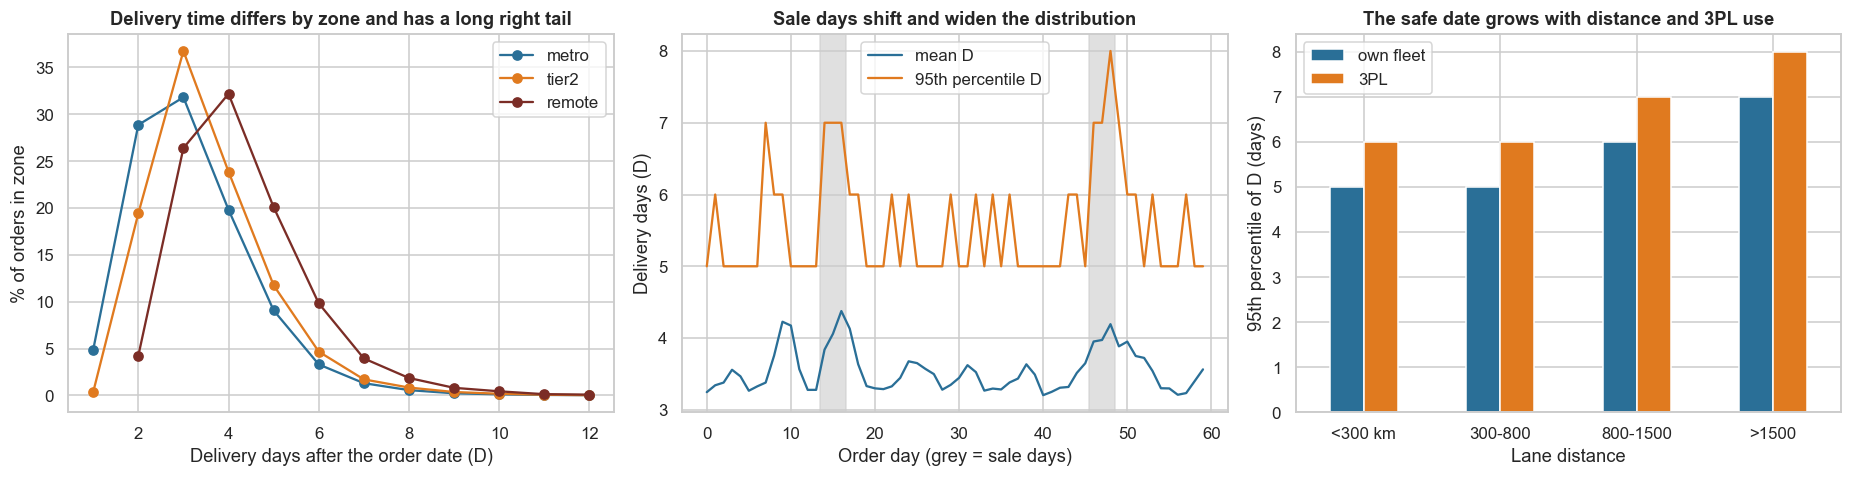

            mean D   sd D  p95 D
period                          
BAU         3.4600 1.3100 6.0000
HRD (sale)  4.0600 1.5700 7.0000
post-HRD    3.9900 1.4500 7.0000
Corr(D, distance) = 0.48; Corr(D, 3PL) = 0.22; Corr(D, vendor item) = 0.37


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for z_, c_ in zip(("metro", "tier2", "remote"), ("#2a6f97", "#e07a1f", "#7b2d26")):
    vc = df[df.zone == z_].D.value_counts(normalize=True).sort_index(); vc = vc[vc.index <= 12]; axes[0].plot(vc.index, vc.values * 100, marker="o", color=c_, label=z_)
axes[0].set_xlabel("Delivery days after the order date (D)"); axes[0].set_ylabel("% of orders in zone"); axes[0].set_title("Delivery time differs by zone and has a long right tail"); axes[0].legend()
g = df.groupby("day").D; axes[1].plot(g.mean().index, g.mean().values, color="#2a6f97", label="mean D"); axes[1].plot(g.quantile(0.95).index, g.quantile(0.95).values, color="#e07a1f", label="95th percentile D")
for lo, hi in ((14, 16), (46, 48)): axes[1].axvspan(lo - 0.5, hi + 0.5, color="#cccccc", alpha=0.6)
axes[1].set_xlabel("Order day (grey = sale days)"); axes[1].set_ylabel("Delivery days (D)"); axes[1].set_title("Sale days shift and widen the distribution"); axes[1].legend()
df["dist_bucket"] = pd.cut(df.distance_km, [0, 300, 800, 1500, 5000], labels=["<300 km", "300-800", "800-1500", ">1500"])
p95 = df.groupby(["dist_bucket", "carrier_3pl"]).D.quantile(0.95).unstack(); p95.columns = ["own fleet", "3PL"]; p95.plot(kind="bar", ax=axes[2], color=["#2a6f97", "#e07a1f"], rot=0)
axes[2].set_xlabel("Lane distance"); axes[2].set_ylabel("95th percentile of D (days)"); axes[2].set_title("The safe date grows with distance and 3PL use")
plt.tight_layout(); plt.show()
ev = df.groupby("period").D.agg(["mean", "std", lambda s: s.quantile(0.95)]); ev.columns = ["mean D", "sd D", "p95 D"]; print(ev.round(2).to_string())
print(f"Corr(D, distance) = {df.D.corr(df.distance_km):.2f}; Corr(D, 3PL) = {df.D.corr(df.carrier_3pl):.2f}; Corr(D, vendor item) = {df.D.corr(df.vendor_item):.2f}")

**Takeaway:** delivery time depends on zone, distance, courier and sale days, and has a long right tail. On BAU days the mean is **3.46 days (sd 1.31, 95th percentile 6)**; on sale days it is **4.06 (sd 1.57, 95th percentile 7)** and after the sale 3.99 (sd 1.45). D correlates 0.48 with distance, 0.37 with a vendor-procured item and 0.22 with 3PL use. A single static number per zone therefore pads many lanes and still fails on others, and a model for the 95th percentile has to be allowed to vary with these drivers and with the calendar.

## 7. Statistical Analysis (core section)

### 7.1 Setup: split in time, nine promise rules

**Protocol (respects time and outcome delay):** train on order days 0-34; **calibrate** on days 35-39; **embargo** days 40-44 (their outcomes are still maturing, as in real life, but they are available later to rolling methods); **test** days 45-59, which contain a sale event (days 46-48) and its aftermath (49-50). The promise is **P = ⌈ prediction ⌉ days**; a **breach** is D > P. The target is α = **5%**.

| # | Rule | In one line |
|---|---|---|
| 1 | Rule-based | Static days per zone: the 94th percentile of D on training days, rounded up to whole days (a stand-in for configured static times) |
| 2 | Mean + 1 day | Gradient boosting with squared loss (predicts the mean), plus one safety day |
| 3 | Asymmetric (expectile) loss | Gradient boosting with weighted squared loss, weight 9 when it under-predicts and 1 otherwise (re-weighted four times) |
| 4 | **Quantile regression** | Gradient boosting with pinball loss at τ = 0.95 |
| 5 | Feedback breach control | Quantile regression plus an offset from the last **3** days of already-delivered orders (the 95th percentile of their residuals) |
| 6 | **Split-conformal** | Quantile regression plus one offset from the calibration days: the ⌈(n+1)(1−α)⌉-th smallest residual |
| 7 | Mondrian conformal | As 6, with a separate offset for each zone |
| 8 | Rolling conformal | As 5, with the last **10** days of delivered orders |
| 9 | Hybrid (added after seeing 7.4) | Split-conformal offset on normal days, plain quantile regression (no offset) on sale and post-sale days. This rule was chosen after seeing the sale-day failure on the same test days, so it needs confirmation on the next sale event |

All models use the same features, fixed settings (100 trees, learning rate 0.15) and no tuning.

#### Code

In [7]:
FEATS = ["hour", "weekday", "is_national_holiday", "is_hrd", "is_post_hrd", "warehouse", "centre", "zone_code", "distance_km", "n_items", "vendor_item", "carrier_3pl",
         "pend_wh_prev_day", "pend_centre_prev_day", "centre_holiday_next2", "planned_volume_ratio", "after_cutoff"]
CATMASK = [f in ("warehouse", "centre", "zone_code") for f in FEATS]
TR = df[df.day <= 34]; POOL = df[df.day >= 35].copy(); CAL = POOL[POOL.day <= 39]; TE = POOL[POOL.day >= 45].copy()
print(f"train {len(TR):,} (days 0-34) | calibration {len(CAL):,} (days 35-39) | embargo {int(((POOL.day >= 40) & (POOL.day <= 44)).sum()):,} (days 40-44) | test {len(TE):,} (days 45-59)")
def hgb(loss="squared_error", q=None):
    kw = dict(loss=loss, max_iter=100, learning_rate=0.15, max_leaf_nodes=31, early_stopping=False, categorical_features=CATMASK, random_state=SEED)
    if q is not None: kw["quantile"] = q
    return HGB(**kw)
HGB = HistGradientBoostingRegressor
Xtr, ytr = TR[FEATS].values, TR.D.values; t0 = time.time()
m_mean = hgb().fit(Xtr, ytr)
m_exp = hgb().fit(Xtr, ytr)
for _ in range(4):
    p_ = m_exp.predict(Xtr); m_exp = hgb().fit(Xtr, ytr, sample_weight=np.where(ytr > p_, 9.0, 1.0))
m_q95 = hgb("quantile", 0.95).fit(Xtr, ytr)
for c_ in ("mean", "exp", "q95"): POOL[c_] = {"mean": m_mean, "exp": m_exp, "q95": m_q95}[c_].predict(POOL[FEATS].values)
print(f"fitted mean, expectile and quantile models in {time.time() - t0:.0f}s")
POOL["s"] = POOL.D - 1 - POOL.q95                  # conformity score on the rounded-promise scale: breach <=> s >= offset, because D is an integer and P = ceil(q + offset)
def conf_offset(s, alpha=0.05):
    s = np.sort(np.asarray(s)); n = len(s); k = int(np.ceil((n + 1) * (1 - alpha))); return s[min(k, n) - 1] + 1e-9 if n else np.nan
C_CAL = conf_offset(POOL.loc[CAL.index, "s"]); ZC = {z: conf_offset(POOL.loc[CAL.index][CAL.zone == z].s) for z in ("metro", "tier2", "remote")}
def roll_offsets(W, alpha=0.05):
    out = {}
    for d in sorted(TE.day.unique()):
        known = POOL[(POOL.day >= d - W) & (POOL.day < d) & (POOL.day + POOL.D < d)]; out[d] = conf_offset(known.s, alpha) if len(known) >= 50 else C_CAL
    return out
OFF3, OFF10 = roll_offsets(3), roll_offsets(10)
RULE = {z: int(np.ceil(TR[TR.zone == z].D.quantile(0.94))) for z in ("metro", "tier2", "remote")}
T_ = POOL.loc[TE.index]; PROM = {
    "1 rule-based (zone table)": T_.zone.map(RULE).values.astype(float),
    "2 mean + 1 day": np.ceil(T_["mean"].values + 1),
    "3 asymmetric (expectile) loss": np.ceil(T_.exp.values),
    "4 quantile regression (0.95)": np.ceil(T_.q95.values),
    "5 feedback control (3-day)": np.ceil(T_.q95.values + T_.day.map(OFF3).values),
    "6 split-conformal": np.ceil(T_.q95.values + C_CAL),
    "7 Mondrian conformal (zone)": np.ceil(T_.q95.values + T_.zone.map(ZC).values),
    "8 rolling conformal (10-day)": np.ceil(T_.q95.values + T_.day.map(OFF10).values)}
PROM["9 hybrid (conformal on BAU, plain QR on sale days)"] = np.where((T_.is_hrd.values == 1) | (T_.is_post_hrd.values == 1), PROM["4 quantile regression (0.95)"], PROM["6 split-conformal"])
MASK = {"BAU": ((T_.is_hrd == 0) & (T_.is_post_hrd == 0)).values, "HRD (sale)": (T_.is_hrd == 1).values, "post-HRD": (T_.is_post_hrd == 1).values}
Dte = T_.D.values
def score(P, m):
    D = Dte[m]; P = P[m]; return dict(n=int(m.sum()), breach=(D > P).mean(), acc01=((P >= D) & (P - D <= 1)).mean(), acc02=((P >= D) & (P - D <= 2)).mean(), mean_promise=P.mean(), slack=np.maximum(P - D, 0).mean())
rows = []
for k, P in PROM.items():
    b, h, p_ = score(P, MASK["BAU"]), score(P, MASK["HRD (sale)"]), score(P, MASK["post-HRD"]); lo, hi = proportion_confint(round(b["breach"] * b["n"]), b["n"], method="wilson")
    rows.append((k, b["breach"], lo, hi, b["acc01"], b["mean_promise"], b["slack"], h["breach"], h["acc02"], p_["breach"]))
res = pd.DataFrame(rows, columns=["method", "BAU breach", "CI low", "CI high", "BAU accuracy (0 to -1)", "BAU mean promise (days)", "BAU slack (days)", "HRD breach", "HRD accuracy (0 to -2)", "post-HRD breach"]).set_index("method")
print(f"Rule-based table: {RULE} | calibration offset {C_CAL:.2f} days | zone offsets { {k: round(v, 2) for k, v in ZC.items()} } | BAU orders {int(MASK['BAU'].sum()):,}, HRD {int(MASK['HRD (sale)'].sum()):,}")
res.round(4)

train 80,667 (days 0-34) | calibration 9,816 (days 35-39) | embargo 10,119 (days 40-44) | test 41,222 (days 45-59)


fitted mean, expectile and quantile models in 84s


Rule-based table: {'metro': 5, 'tier2': 6, 'remote': 7} | calibration offset -1.01 days | zone offsets {'metro': np.float64(-1.05), 'tier2': np.float64(-0.98), 'remote': np.float64(-1.3)} | BAU orders 20,086, HRD 15,630


,BAU breach,CI low,CI high,BAU accuracy (0 to -1),BAU mean promise (days),BAU slack (days),HRD breach,HRD accuracy (0 to -2),post-HRD breach
method,,,,,,,,,
1 rule-based (zone table),0.0203,0.0185,0.0224,0.1657,5.9672,2.5386,0.0677,0.5221,0.0637
2 mean + 1 day,0.0193,0.0175,0.0213,0.3636,5.0623,1.6321,0.0598,0.8599,0.0490
3 asymmetric (expectile) loss,0.0232,0.0212,0.0254,0.5981,4.7420,1.3179,0.0692,0.8541,0.0603
4 quantile regression (0.95),0.0128,0.0113,0.0144,0.3740,5.2900,1.8479,0.0458,0.7264,0.0429
5 feedback control (3-day),0.3441,0.3375,0.3507,0.5653,3.4701,0.4385,0.4434,0.5414,0.4223
6 split-conformal,0.0487,0.0458,0.0518,0.7367,4.2794,0.8867,0.0960,0.8457,0.1181
7 Mondrian conformal (zone),0.0489,0.0460,0.0520,0.7536,4.2355,0.8441,0.1013,0.8443,0.1224
8 rolling conformal (10-day),0.0691,0.0656,0.0726,0.6672,4.3569,0.9835,0.1068,0.8404,0.1420
"9 hybrid (conformal on BAU, plain QR on sale days)",0.0487,0.0458,0.0518,0.7367,4.2794,0.8867,0.0458,0.7264,0.0429


**Observation:** **Plain quantile regression has the lowest BAU breach among the unconformalised rules (1.3%, CI 1.1% to 1.4%) but it is over-cautious**: the target is 5%, so it wastes padding (mean promise 5.29 days, accuracy 37.4%). The rule-based table has 2.0% breach, 5.97 days and only **16.6%** accuracy. Mean + 1 day gives 1.9% breach and 36.4% accuracy. The expectile (asymmetric loss) model gives 2.3% breach and 59.8% accuracy, so asymmetric loss lands on a breach rate that nobody chose, which echoes the paper's remark that it cannot control breaches deterministically. **Split-conformal hits the target on BAU days (4.9%, accuracy 73.7%, mean promise 4.28 days)**, and Mondrian by zone is almost identical (4.9%, 75.4%). On sale days all fixed rules breach more: rule-based 6.8%, quantile regression 4.6%, split-conformal **9.6%**. After the sale: 6.4%, 4.3% and **11.8%**. The 3-day feedback rule collapses (BAU 34.4%) and the 10-day rolling rule overshoots (BAU 6.9%, sale 10.7%). The hybrid equals split-conformal on BAU and plain quantile regression on sale days (4.6% and 4.3%).

### 7.2 Is the 5% breach target really met? Exact test and day-level cluster bootstrap

**(a) Why?** A breach rate of 4.8% on 30,000 orders sounds fine, but orders on the same day share backlogs, so they are **not independent**. We test H0: breach ≤ 5% on BAU days in two ways: an exact binomial test (assumes independence, so it is optimistic) and a **bootstrap that resamples whole days** (the honest unit). Holm adjusts across the eight methods.

#### Code

In [8]:
mb = MASK["BAU"]; days_b = T_.day.values[mb]; ud = np.unique(days_b); rows = []
for k, P in PROM.items():
    br = (Dte[mb] > P[mb]); n = len(br); x = int(br.sum()); p_ex = stats.binomtest(x, n, 0.05, alternative="greater").pvalue
    per_day = pd.Series(br).groupby(days_b).agg(["sum", "count"]); bs = []
    for _ in range(2000):
        pick = RNG.choice(len(per_day), len(per_day)); bs.append(per_day["sum"].values[pick].sum() / per_day["count"].values[pick].sum())
    rows.append((k, x / n, np.percentile(bs, 2.5), np.percentile(bs, 97.5), p_ex, np.mean(np.array(bs) <= 0.05)))
tg = pd.DataFrame(rows, columns=["method", "BAU breach", "day-bootstrap CI low", "day-bootstrap CI high", "exact p (H0: ≤ 5%)", "share of bootstrap draws ≤ 5%"]).set_index("method")
tg["p_holm"] = multipletests(tg["exact p (H0: ≤ 5%)"], method="holm")[1]; tg["meets 5% (CI high ≤ 5%)"] = tg["day-bootstrap CI high"] <= 0.05
dr = pd.Series(~(Dte[mb] > PROM["4 quantile regression (0.95)"][mb])).groupby(days_b).mean(); msb = dr.var(ddof=1) * len(dr)  # rough ICC via daily breach variance
dbr = pd.Series(Dte[mb] > PROM["4 quantile regression (0.95)"][mb]).groupby(days_b).agg(["mean", "count"]); mbar = dbr["count"].mean(); gm = dbr["mean"].mean()
icc = max(0.0, (dbr["mean"].var(ddof=1) - gm * (1 - gm) / mbar) / (gm * (1 - gm)))
print(f"BAU days in test: {len(ud)} | orders per day ≈ {mbar:,.0f} | between-day variance of the quantile-regression breach rate gives ICC ≈ {icc:.4f}, design effect ≈ {1 + (mbar - 1) * icc:.1f}")
tg.round(4)

BAU days in test: 10 | orders per day ≈ 2,009 | between-day variance of the quantile-regression breach rate gives ICC ≈ 0.0006, design effect ≈ 2.2


,BAU breach,day-bootstrap CI low,day-bootstrap CI high,exact p (H0: ≤ 5%),share of bootstrap draws ≤ 5%,p_holm,meets 5% (CI high ≤ 5%)
method,,,,,,,
1 rule-based (zone table),0.0203,0.0174,0.0233,1.0000,1.0000,1.0000,True
2 mean + 1 day,0.0193,0.0162,0.0224,1.0000,1.0000,1.0000,True
3 asymmetric (expectile) loss,0.0232,0.0188,0.0283,1.0000,1.0000,1.0000,True
4 quantile regression (0.95),0.0128,0.0106,0.0149,1.0000,1.0000,1.0000,True
5 feedback control (3-day),0.3441,0.2057,0.5078,0.0000,0.0000,0.0000,False
6 split-conformal,0.0487,0.0380,0.0592,0.8069,0.5715,1.0000,False
7 Mondrian conformal (zone),0.0489,0.0382,0.0600,0.7591,0.5610,1.0000,False
8 rolling conformal (10-day),0.0691,0.0377,0.1085,0.0000,0.1290,0.0000,False
"9 hybrid (conformal on BAU, plain QR on sale days)",0.0487,0.0378,0.0595,0.8069,0.5780,1.0000,False


**Observation:** on BAU days the rule-based table, mean + 1 day, expectile and plain quantile regression all sit under 5% (day-bootstrap CI upper limits 2.3%, 2.2%, 2.8% and 1.5%), so on breach alone they are safe but loose. **Split-conformal (4.9%, CI 3.8% to 5.9%) and Mondrian (4.9%, CI 3.8% to 6.0%) cannot be distinguished from 5%** (exact p = 0.81 and 0.76; the exact test is optimistic because orders on a day are correlated, so we rely on the bootstrap CI). The 3-day feedback rule (34.4%) fails, and the rolling 10-day rule (6.9%, CI 3.8% to 10.9%) is not certifiable (exact Holm p below 1e-4). The estimated ICC of daily breach for plain quantile regression is only 0.0006, but with about 2,000 orders a day the design effect is 2.2, so the effective sample is less than half of the nominal one. With only 10 BAU test days, the day-level CIs are wide (about ±1 percentage point).

### 7.3 Is quantile regression really better than the rule-based table? Paired tests

**(a) Why?** Both rules are scored on the **same orders**, so McNemar on paired outcomes is right: (i) breach (late vs not late) and (ii) accuracy (on the promised date or one day early). We compare quantile regression (rule 4) with the rule-based table (rule 1), mean + 1 day (rule 2) and the expectile model (rule 3). Holm across the six tests. The effect size is the difference in rates with a day-bootstrap CI.

#### Code

In [9]:
from statsmodels.stats.contingency_tables import mcnemar
def paired(Pa, Pb, kind):
    a = (Dte[mb] > Pa[mb]) if kind == "breach" else ((Pa[mb] >= Dte[mb]) & (Pa[mb] - Dte[mb] <= 1)); b = (Dte[mb] > Pb[mb]) if kind == "breach" else ((Pb[mb] >= Dte[mb]) & (Pb[mb] - Dte[mb] <= 1))
    mc = mcnemar([[int((a & b).sum()), int((a & ~b).sum())], [int((~a & b).sum()), int((~a & ~b).sum())]], exact=False, correction=True)
    diff = pd.Series(a.astype(float) - b.astype(float)).groupby(days_b).mean(); bs = [diff.values[RNG.integers(0, len(diff), len(diff))].mean() for _ in range(2000)]
    return a.mean() - b.mean(), np.percentile(bs, 2.5), np.percentile(bs, 97.5), int((a & ~b).sum()), int((~a & b).sum()), mc.pvalue
rows = []
for kind in ("breach", "accuracy"):
    for other in ("1 rule-based (zone table)", "2 mean + 1 day", "3 asymmetric (expectile) loss"):
        d, lo, hi, n10, n01, p = paired(PROM["4 quantile regression (0.95)"], PROM[other], kind); rows.append((kind, other, d, lo, hi, n10, n01, p))
pt = pd.DataFrame(rows, columns=["metric", "QR (rule 4) minus", "difference (pp as fraction)", "CI low", "CI high", "only QR event", "only other event", "McNemar p"]); pt["p_holm"] = multipletests(pt["McNemar p"], method="holm")[1]
pt.round(4)

,metric,QR (rule 4) minus,difference (pp as fraction),CI low,CI high,only QR event,only other event,McNemar p,p_holm
0,breach,1 rule-based (zone table),-0.0075,-0.0103,-0.0048,98,249,0.0000,0.0000
1,breach,2 mean + 1 day,-0.0065,-0.0087,-0.0044,19,149,0.0000,0.0000
2,breach,3 asymmetric (expectile) loss,-0.0104,-0.0147,-0.0074,2,211,0.0000,0.0000
3,accuracy,1 rule-based (zone table),0.2083,0.1109,0.2931,5770,1586,0.0000,0.0000
4,accuracy,2 mean + 1 day,0.0104,-0.0477,0.0680,2110,1902,0.0011,0.0011
5,accuracy,3 asymmetric (expectile) loss,-0.2241,-0.2618,-0.1889,253,4755,0.0000,0.0000


**Observation:** **Quantile regression has fewer breaches than every other unconformalised rule on the same orders**: 0.75 percentage points fewer than the rule-based table (CI 0.48 to 1.03; 98 orders breached only under quantile regression against 249 only under the table), 0.65 fewer than mean + 1 day and 1.04 fewer than the expectile model (all Holm p below 1e-4). **Accuracy is much higher than the table** (+20.8 points, CI 11.1 to 29.3). Against mean + 1 day the accuracy difference is +1.0 point with a day-bootstrap CI of -4.8 to +6.8, so the two are not distinguishable on accuracy at the day level, even though McNemar on orders gives p = 0.001 (the order-level test ignores day clustering). The expectile model is more accurate than quantile regression (quantile regression is 22.4 points lower) only because it sits at a less safe place on the frontier, with a higher breach rate (2.3% against 1.3%).

### 7.4 The conformal guarantee: does the coverage follow the theory?

**(a) Why?** If calibration and future orders are **exchangeable**, split-conformal promises coverage of at least 1 − α with a **known finite-sample law**: with n calibration orders and k = ⌈(n+1)(1−α)⌉, coverage over random calibration sets follows a **Beta(k, n+1−k)** distribution, with mean k/(n+1) and standard deviation about √(α(1−α)/n). We check this on the calibration days (where exchangeability is plausible) by drawing random calibration subsets of 100, 500 and 2,000 orders, scoring coverage on the remaining orders, 400 times each (random order-level splits, so day clustering is ignored here by design). Then we ask the practical question: does the offset **transfer** to the test days (H5: KS test of residuals)?

#### Code

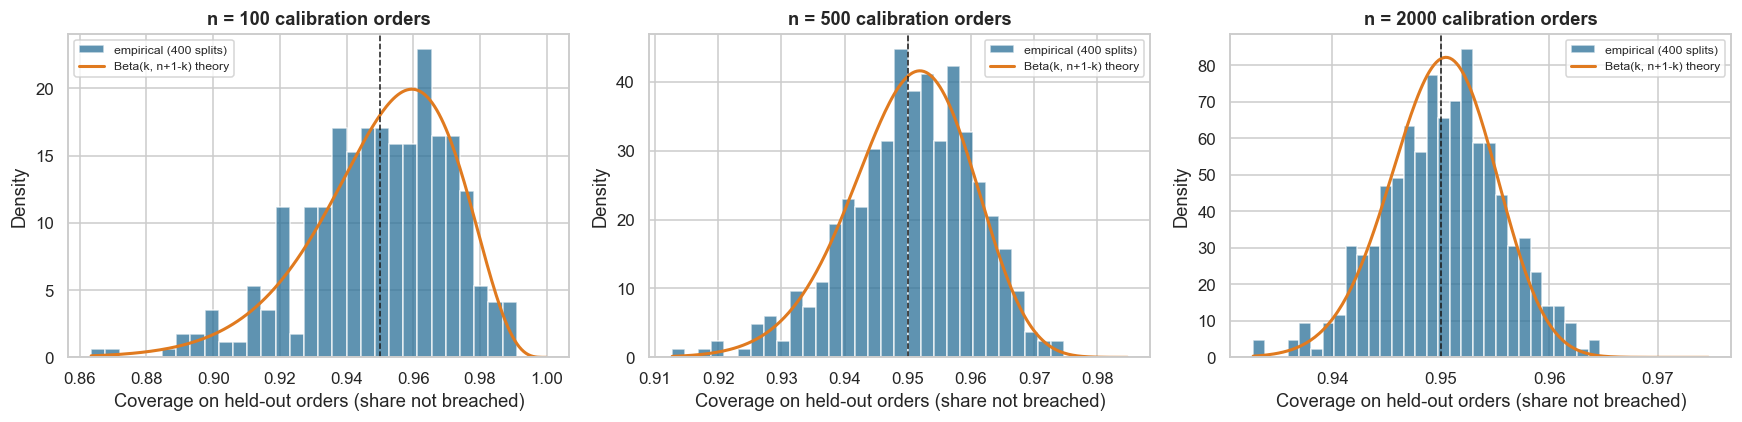

               mean coverage (empirical)  mean coverage (theory)  sd (empirical)  sd (theory)  share of splits below 95% (empirical)  share below 95% (theory)  KS p vs Beta
calibration n                                                                                                                                                               
100                               0.9495                  0.9505          0.0218       0.0215                                 0.4650                    0.4360        0.4933
500                               0.9505                  0.9501          0.0101       0.0097                                 0.4525                    0.4714        0.2779
2000                              0.9503                  0.9500          0.0055       0.0049                                 0.4825                    0.4857        0.2512



Split-conformal offset -1.01 days. Coverage on test days: BAU 95.1%, HRD (sale) 90.4%, post-HRD 88.2%
Mean score (D minus 1 minus 95% prediction): calibration -2.37, BAU test -2.33, HRD -2.31, post-HRD -2.10
KS tests of residuals vs calibration days: BAU D = 0.026 (p = 0.00037); HRD D = 0.063 (p = 4.2e-21); post-HRD D = 0.109 (p = 9.3e-37)


In [10]:
sc = POOL.loc[CAL.index, "s"].values; fig, axes = plt.subplots(1, 3, figsize=(16, 4)); rows = []
for ax, n in zip(axes, (100, 500, 2000)):
    cov = []
    for _ in range(400):
        pm = RNG.permutation(len(sc)); c_ = conf_offset(sc[pm[:n]]); cov.append((sc[pm[n:]] <= c_).mean())
    cov = np.array(cov); k = int(np.ceil((n + 1) * 0.95)); bd = stats.beta(k, n + 1 - k)
    ax.hist(cov, bins=30, density=True, color="#2a6f97", alpha=0.75, label="empirical (400 splits)"); xs = np.linspace(cov.min(), min(1, cov.max() + 0.01), 200); ax.plot(xs, bd.pdf(xs), color="#e07a1f", lw=2, label="Beta(k, n+1-k) theory"); ax.axvline(0.95, color="k", ls="--", lw=1)
    ax.set_xlabel("Coverage on held-out orders (share not breached)"); ax.set_ylabel("Density"); ax.set_title(f"n = {n} calibration orders"); ax.legend(fontsize=8)
    rows.append((n, cov.mean(), k / (n + 1), cov.std(), bd.std(), (cov < 0.95).mean(), bd.cdf(0.95), stats.kstest(cov, bd.cdf).pvalue))
plt.tight_layout(); plt.show()
cg = pd.DataFrame(rows, columns=["calibration n", "mean coverage (empirical)", "mean coverage (theory)", "sd (empirical)", "sd (theory)", "share of splits below 95% (empirical)", "share below 95% (theory)", "KS p vs Beta"]).set_index("calibration n")
print(cg.round(4).to_string())
sTE = POOL.loc[TE.index, "s"].values; ks_b = stats.ks_2samp(sc, sTE[MASK["BAU"]]); ks_h = stats.ks_2samp(sc, sTE[MASK["HRD (sale)"]]); ks_p = stats.ks_2samp(sc, sTE[MASK["post-HRD"]])
cov_t = {k: (sTE[m] <= C_CAL).mean() for k, m in MASK.items()}
print(f"\nSplit-conformal offset {C_CAL:.2f} days. Coverage on test days: " + ", ".join(f"{k} {v:.1%}" for k, v in cov_t.items()))
print(f"Mean score (D minus 1 minus 95% prediction): calibration {sc.mean():+.2f}, BAU test {sTE[MASK['BAU']].mean():+.2f}, HRD {sTE[MASK['HRD (sale)']].mean():+.2f}, post-HRD {sTE[MASK['post-HRD']].mean():+.2f}")
print(f"KS tests of residuals vs calibration days: BAU D = {ks_b.statistic:.3f} (p = {ks_b.pvalue:.2g}); HRD D = {ks_h.statistic:.3f} (p = {ks_h.pvalue:.2g}); post-HRD D = {ks_p.statistic:.3f} (p = {ks_p.pvalue:.2g})")

**Takeaway:** the finite-sample theory holds: for 100, 500 and 2,000 calibration orders the mean coverage over 400 random splits was **94.87%, 94.97% and 95.00%** against 95.05%, 95.01% and 95.00% by the Beta law; the spread matched (0.0233, 0.0094, 0.0051 against 0.0215, 0.0097, 0.0049) and the KS tests against the Beta law gave p = 0.34, 0.69 and 0.69. Small calibration sets are noisy: with n = 100, 47% of calibrations fall below 95% coverage (theory 44%). The offset transfers to normal test days (**coverage 95.1%**) but **not to the sale (90.4%) or the post-sale days (88.2%)**. Mean scores are nearly equal (-2.37 in calibration, -2.33 BAU, -2.31 HRD, -2.10 post-sale), so the failure is in the shape of the tail, which the KS test confirms (D = 0.026 BAU with p = 0.0004; 0.063 on sale days; 0.109 post-sale, p below 1e-20). With 41,000 test orders even a small shift is significant, but the sale-day shift is large enough to matter.

### 7.5 For whom does the guarantee fail? Breach by segment and a heterogeneity test

**(a) Why?** A marginal 5% can hide 2% in metros and 12% in remote areas. A single conformal offset only guarantees the **average**. We split the test orders (all periods together for period rows; BAU only for the others) into 12 segments, show breach by method as a heatmap, and test **homogeneity** with a chi-square test per segmentation and method (Holm across all 12 tests).

#### Code

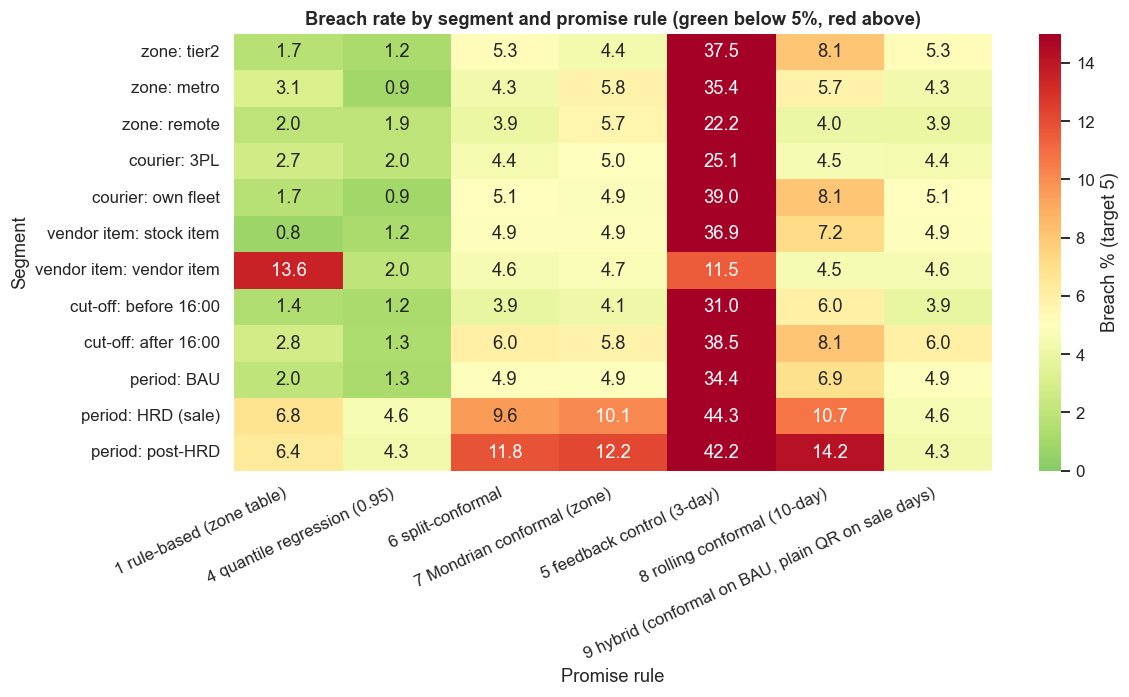

Breach % by segment (test orders):
                          1 rule-based (zone table)  4 quantile regression (0.95)  6 split-conformal  7 Mondrian conformal (zone)  5 feedback control (3-day)  8 rolling conformal (10-day)  9 hybrid (conformal on BAU, plain QR on sale days)      orders
zone: tier2                                  1.7000                        1.2000             5.3000                       4.4000                     37.5000                        8.1000                                              5.3000 12,419.0000
zone: metro                                  3.1000                        0.9000             4.3000                       5.8000                     35.4000                        5.7000                                              4.3000  4,163.0000
zone: remote                                 2.0000                        1.9000             3.9000                       5.7000                     22.2000                        4.0000                      

In [11]:
SEG = {"zone": T_.zone.values, "courier": np.where(T_.carrier_3pl == 1, "3PL", "own fleet"), "vendor item": np.where(T_.vendor_item == 1, "vendor item", "stock item"), "cut-off": np.where(T_.after_cutoff == 1, "after 16:00", "before 16:00"), "period": T_.period.values}
HM = {k: PROM[k] for k in ("1 rule-based (zone table)", "4 quantile regression (0.95)", "6 split-conformal", "7 Mondrian conformal (zone)", "5 feedback control (3-day)", "8 rolling conformal (10-day)", "9 hybrid (conformal on BAU, plain QR on sale days)")}
rows, lab, ptab = {}, [], []
for sname, sv in SEG.items():
    for lv in pd.unique(sv):
        m = (sv == lv) & (mb if sname != "period" else np.ones(len(sv), bool)); lab.append(f"{sname}: {lv}"); rows[lab[-1]] = {k: (Dte[m] > P[m]).mean() for k, P in HM.items()} | {"orders": int(m.sum())}
    base = mb if sname != "period" else np.ones(len(sv), bool)
    for k, P in HM.items():
        tab = pd.crosstab(sv[base], (Dte[base] > P[base])); tab = tab.reindex(columns=[False, True], fill_value=0); ptab.append((sname, k, stats.chi2_contingency(tab.values)[1]))
hm = pd.DataFrame(rows).T; hp = pd.DataFrame(ptab, columns=["segmentation", "method", "chi2 p"]).pivot(index="segmentation", columns="method", values="chi2 p")
hp_adj = pd.DataFrame(multipletests(hp.values.ravel(), method="holm")[1].reshape(hp.shape), index=hp.index, columns=hp.columns)
fig, ax = plt.subplots(figsize=(11, 6.5)); sns.heatmap(hm.drop(columns="orders") * 100, annot=True, fmt=".1f", cmap="RdYlGn_r", center=5, vmin=0, vmax=15, cbar_kws={"label": "Breach % (target 5)"}, ax=ax)
ax.set_title("Breach rate by segment and promise rule (green below 5%, red above)"); ax.set_xlabel("Promise rule"); ax.set_ylabel("Segment"); plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()
print("Breach % by segment (test orders):"); print((hm.assign(**{c: hm[c] * 100 for c in hm.columns if c != "orders"})).round(1).to_string()); print()
print("Holm-adjusted chi-square p-values for H4 (breach equal across the levels of each segmentation):"); print(hp_adj.round(4).to_string())
worst = (hm.drop(columns="orders").max()).round(3); print("\nWorst-segment breach by method:", worst.to_dict())

**Takeaway:** under one conformal offset the marginal 5% hides differences. On BAU days split-conformal breach is **5.3% in tier-2, 4.3% in metro and 3.9% in remote**, 5.1% for own-fleet orders and 4.4% for 3PL, and **6.0% for orders placed after 16:00 against 3.9% before**. Zone differences stay significant after Holm adjustment (p = 0.008 for split-conformal, 0.002 for Mondrian), as do cut-off differences (p below 1e-4), while courier and vendor-item gaps are not significant (p = 0.44 and 1.0). Mondrian by zone does not remove the zone differences (tier-2 4.4%, metro 5.8%, remote 5.7%), because the other drivers still differ inside each zone. The big failures are by period: split-conformal reaches 9.6% on sale days and 11.8% after, and the rule-based table fails on vendor items (13.6%). Plain quantile regression has no segment above 4.6% but over-covers everywhere (BAU segments 0.9% to 2.0%). The hybrid has a worst segment of 6.0% (orders after 16:00) and no significant difference by period (p = 0.87).

### 7.6 Drift on sale days: daily breach and the cost of delayed feedback

**(a) Why?** Models are trained on normal weeks, but sale days change the process (more backlog, cut-offs slip). A fixed offset cannot know. Feedback methods adapt, but only from orders that are **already delivered**: an order placed yesterday is not delivered yet, so recent feedback is biased toward fast orders. We plot daily breach by method and measure the **mean offset** each method applied, the share of the window that was usable (delivered) and the correlation of daily breach with the previous day's breach.

#### Code

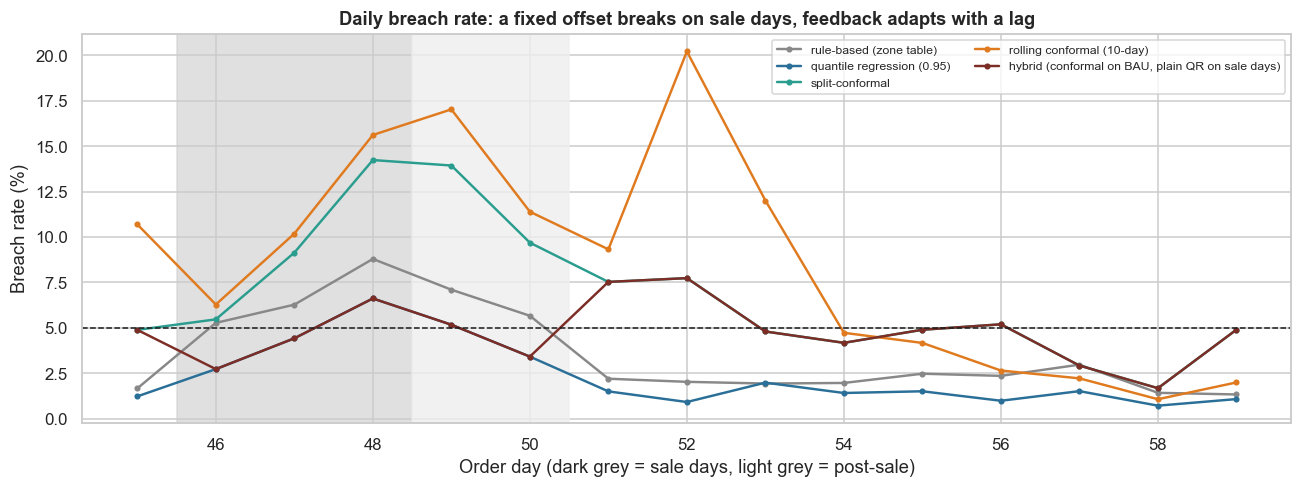

Usable feedback (average over test days):
               delivered share of window  covered at offset 0, delivered only  covered at offset 0, all in window
window                                                                                                           
10-day window                     0.6280                               0.9890                              0.9710
3-day window                      0.0660                               1.0000                              0.9750

Mean offset applied (days): split-conformal -1.01; feedback 3-day -1.91 (range -2.8 to -1.0); rolling 10-day -0.99 (range -1.2 to -0.5)
Daily breach (%): rule-based (zone table): BAU mean 2.0, HRD mean 6.8; quantile regression (0.95): BAU mean 1.3, HRD mean 4.6; split-conformal: BAU mean 4.9, HRD mean 9.6; rolling conformal (10-day): BAU mean 6.9, HRD mean 10.7; hybrid (conformal on BAU, plain QR on sale days): BAU mean 4.9, HRD mean 4.6
Lag-1 autocorrelation of daily breach: {'rule-based (zone t

In [12]:
dayb = pd.DataFrame({k.split(" ", 1)[1]: pd.Series(Dte > P).groupby(T_.day.values).mean() * 100 for k, P in PROM.items() if k[0] in "14689"})
fig, ax = plt.subplots(figsize=(12, 4.6)); cols = ["#888888", "#2a6f97", "#2a9d8f", "#e07a1f", "#7b2d26"]
for c_, col in zip(dayb.columns, cols): ax.plot(dayb.index, dayb[c_], marker="o", ms=3, lw=1.6, label=c_, color=col)
ax.axhline(5, color="k", ls="--", lw=1); ax.axvspan(45.5, 48.5, color="#cccccc", alpha=0.6); ax.axvspan(48.5, 50.5, color="#eeeeee", alpha=0.8)
ax.set_xlabel("Order day (dark grey = sale days, light grey = post-sale)"); ax.set_ylabel("Breach rate (%)"); ax.set_title("Daily breach rate: a fixed offset breaks on sale days, feedback adapts with a lag"); ax.legend(fontsize=8, ncol=2); plt.tight_layout(); plt.show()
share = []
for d in sorted(TE.day.unique()):
    for W, nm in ((3, "3-day window"), (10, "10-day window")):
        win = POOL[(POOL.day >= d - W) & (POOL.day < d)]; kn = win[win.day + win.D < d]; share.append((d, nm, len(kn) / max(len(win), 1), (kn.s < 0).mean() if len(kn) else np.nan, win.s.lt(0).mean()))
sh = pd.DataFrame(share, columns=["day", "window", "delivered share of window", "covered at offset 0, delivered only", "covered at offset 0, all in window"]).groupby("window").mean().drop(columns="day")
print("Usable feedback (average over test days):"); print(sh.round(3).to_string())
print(f"\nMean offset applied (days): split-conformal {C_CAL:.2f}; feedback 3-day {np.mean(list(OFF3.values())):.2f} (range {min(OFF3.values()):.1f} to {max(OFF3.values()):.1f}); rolling 10-day {np.mean(list(OFF10.values())):.2f} (range {min(OFF10.values()):.1f} to {max(OFF10.values()):.1f})")
print("Daily breach (%): " + "; ".join(f"{k}: BAU mean {v[~T_.groupby('day').is_hrd.max().astype(bool).values & ~T_.groupby('day').is_post_hrd.max().astype(bool).values].mean():.1f}, HRD mean {v[T_.groupby('day').is_hrd.max().astype(bool).values].mean():.1f}" for k, v in dayb.items()))
ac = {k: dayb[k].autocorr(1) for k in dayb.columns}; print("Lag-1 autocorrelation of daily breach:", {k: round(v, 2) for k, v in ac.items()})

**Takeaway:** a fixed offset breaks on the sale: daily breach for split-conformal averages 4.9% on normal days and 9.6% on sale days; the rolling 10-day rule averages 6.9% on BAU and 10.7% on sale days, so recent feedback does not rescue it. The reason is delayed outcomes: only **6.6% of the last-3-day window and 62.8% of the last-10-day window** has been delivered when the correction is computed, and those orders are the fast ones (coverage at offset 0 is 100% among delivered orders in the 3-day window against 97.5% in the whole window). The 3-day rule therefore sets very negative offsets (mean -1.91 days, down to -2.8) and breaches 34% of BAU orders. Daily breach of the fixed rules is strongly autocorrelated (0.73 to 0.76), meaning bad days come in runs; the hybrid, which resets to plain quantile regression on sale days, has 4.9% on normal days and 4.6% on sale days and an autocorrelation of 0.23.

### 7.7 The accuracy-vs-breach frontier: what does a tighter promise cost?

**(a) Why?** Every rule trades **breach** against **accuracy (padding)**. Raising τ buys fewer breaches at the price of later promises. The fair comparison between model families is **accuracy at the same breach rate**. We sweep τ ∈ {0.5, 0.8, 0.9, 0.95, 0.99} for quantile regression and the safety buffer (0 to 3 days) for the mean model on BAU test days, interpolate accuracy at 5% breach, and add a pinball-loss (τ = 0.95) comparison with a day-cluster bootstrap.

#### Code

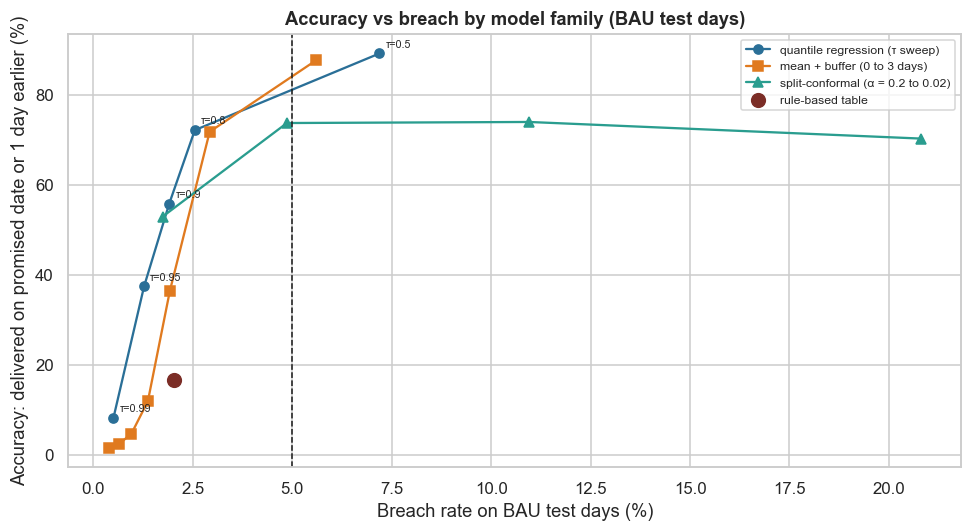

Accuracy at 5% breach (interpolated): quantile regression 81.1%, mean + buffer 84.0%, conformal 73.7% | rule-based 16.6% at 2.0% breach
Quantile crossing check on test orders (share where a higher tau gives a lower prediction): {'0.5->0.8': 0.1073, '0.8->0.9': 0.1169, '0.9->0.95': 0.1191, '0.95->0.99': 0.0176}


,pinball loss (τ = 0.95),minus QR,CI low (day bootstrap),CI high
model,,,,
quantile regression (0.95),0.1486,0.0000,0.0000,0.0000
mean + empirical 95% residual buffer,0.1583,0.0097,0.0038,0.0117
expectile (k = 9),0.1766,0.0280,0.0108,0.0335
rule-based table,0.1945,0.0458,0.0403,0.0582


In [13]:
TAUS = (0.50, 0.80, 0.90, 0.95, 0.99); QS = {}; t0 = time.time()
for tau in TAUS:
    QS[tau] = m_q95 if tau == 0.95 else hgb("quantile", tau).fit(Xtr, ytr)
qpred = {tau: QS[tau].predict(T_[FEATS].values) for tau in TAUS}
def bm(P): return (Dte[mb] > P[mb]).mean() * 100, ((P[mb] >= Dte[mb]) & (P[mb] - Dte[mb] <= 1)).mean() * 100, P[mb].mean()
fq = pd.DataFrame([(t, *bm(np.ceil(qpred[t]))) for t in TAUS], columns=["tau", "breach %", "accuracy %", "mean promise"])
bufs = (0, 0.5, 1, 1.5, 2, 2.5, 3); fm = pd.DataFrame([(b, *bm(np.ceil(T_["mean"].values + b))) for b in bufs], columns=["buffer days", "breach %", "accuracy %", "mean promise"])
qcq = {a: conf_offset(POOL.loc[CAL.index, "s"], a) for a in (0.2, 0.1, 0.05, 0.02)}; fc = pd.DataFrame([(a, *bm(np.ceil(T_.q95.values + c))) for a, c in qcq.items()], columns=["alpha", "breach %", "accuracy %", "mean promise"])
def acc_at(f, target=5.0):
    f = f.sort_values("breach %"); return float(np.interp(target, f["breach %"].values[::-1][::-1], f["accuracy %"].values))
rb = score(PROM["1 rule-based (zone table)"], mb)
fig, ax = plt.subplots(figsize=(9, 5)); ax.plot(fq["breach %"], fq["accuracy %"], marker="o", color="#2a6f97", label="quantile regression (τ sweep)"); ax.plot(fm["breach %"], fm["accuracy %"], marker="s", color="#e07a1f", label="mean + buffer (0 to 3 days)")
ax.plot(fc["breach %"], fc["accuracy %"], marker="^", color="#2a9d8f", label="split-conformal (α = 0.2 to 0.02)"); ax.scatter([rb["breach"] * 100], [rb["acc01"] * 100], color="#7b2d26", s=80, zorder=5, label="rule-based table"); ax.axvline(5, color="k", ls="--", lw=1)
for _, r in fq.iterrows(): ax.annotate(f"τ={r.tau:g}", (r["breach %"], r["accuracy %"]), fontsize=7, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("Breach rate on BAU test days (%)"); ax.set_ylabel("Accuracy: delivered on promised date or 1 day earlier (%)"); ax.set_title("Accuracy vs breach by model family (BAU test days)"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()
a_q, a_m, a_c = acc_at(fq), acc_at(fm), acc_at(fc)
print(f"Accuracy at 5% breach (interpolated): quantile regression {a_q:.1f}%, mean + buffer {a_m:.1f}%, conformal {a_c:.1f}% | rule-based {rb['acc01'] * 100:.1f}% at {rb['breach'] * 100:.1f}% breach")
print("Quantile crossing check on test orders (share where a higher tau gives a lower prediction):", {f"{a}->{b}": round(float((qpred[b] < qpred[a]).mean()), 4) for a, b in zip(TAUS[:-1], TAUS[1:])})
def pin(y, q, tau=0.95): u = y - q; return np.maximum(tau * u, (tau - 1) * u)
cand = {"quantile regression (0.95)": T_.q95.values, "mean + empirical 95% residual buffer": T_["mean"].values + conf_offset(CAL.D.values - POOL.loc[CAL.index, "mean"].values), "expectile (k = 9)": T_.exp.values, "rule-based table": PROM["1 rule-based (zone table)"]}
base_loss = pin(Dte, cand["quantile regression (0.95)"]); rows = []
for k, q in cand.items():
    ls = pin(Dte, q); diff = pd.Series(ls - base_loss).groupby(T_.day.values).mean(); bs = [diff.values[RNG.integers(0, len(diff), len(diff))].mean() for _ in range(2000)]
    rows.append((k, ls.mean(), (ls - base_loss).mean(), np.percentile(bs, 2.5), np.percentile(bs, 97.5)))
pl = pd.DataFrame(rows, columns=["model", "pinball loss (τ = 0.95)", "minus QR", "CI low (day bootstrap)", "CI high"]).set_index("model"); print(); pl.round(4)

**Takeaway:** **On this test, the mean + buffer family reaches higher accuracy at 5% breach than quantile regression** (interpolated 84.0% against 81.1%; conformal 73.7% from only four points), so we cannot claim that quantile regression dominates a well-set buffer on the frontier. Its advantage is elsewhere: the pinball loss at 0.95 is lowest (0.149; mean + empirical residual buffer 0.158, expectile 0.177, rule-based table 0.195), and the gap to the next best is 0.0097 (day-bootstrap CI 0.004 to 0.012). The rule-based table sits far inside the frontier (16.6% accuracy at 2.0% breach). A caution: the quantile predictions **cross**: a higher τ gives a lower prediction for 10.7% (0.5 to 0.8), 11.7% (0.8 to 0.9), 11.9% (0.9 to 0.95) and 1.8% (0.95 to 0.99) of test orders, because each τ is fitted separately and the target is whole days. Rounding to days makes the frontier a staircase, which is why accuracy-at-breach comparisons are noisy.

### 7.8 Which drivers lift the safe date? A linear quantile regression for interpretation

**(a) Why?** Gradient boosting predicts well but is hard to read. A linear **quantile regression at τ = 0.95** on 30,000 training orders (statsmodels) tells the business how many extra days the safe date needs for a 3PL shipment, a vendor item, remote zones, an after-cut-off order or a sale day. Each coefficient is the shift of the 95th percentile of D; Holm-adjusted p-values across the coefficients.

#### Code

In [14]:
sm_tr = TR.sample(30000, random_state=SEED).copy(); sm_tr["remote"] = (sm_tr.zone == "remote").astype(int); sm_tr["tier2"] = (sm_tr.zone == "tier2").astype(int); sm_tr["dist_000km"] = sm_tr.distance_km / 1000
form = "D ~ is_hrd + is_post_hrd + carrier_3pl + vendor_item + after_cutoff + multi + remote + tier2 + dist_000km + pend_centre_prev_day + pend_wh_prev_day"
qr = smf.quantreg(form, sm_tr).fit(q=0.95, max_iter=2000); cf = pd.DataFrame({"shift in 95th percentile of D (days)": qr.params, "CI low": qr.conf_int()[0], "CI high": qr.conf_int()[1], "p": qr.pvalues}).drop("Intercept")
cf["p_holm"] = multipletests(cf.p, method="holm")[1]; q50 = smf.quantreg(form, sm_tr).fit(q=0.5, max_iter=2000); cf["shift at the median"] = q50.params.drop("Intercept")
print(f"Pseudo R² (τ = 0.95) = {qr.prsquared:.3f}; intercept {qr.params['Intercept']:.2f} days"); cf.round(4)

Pseudo R² (τ = 0.95) = 0.303; intercept 3.03 days


,shift in 95th percentile of D (days),CI low,CI high,p,p_holm,shift at the median
is_hrd,1.3640,1.2768,1.4512,0.0000,0.0000,0.3675
is_post_hrd,0.9239,0.7179,1.1299,0.0000,0.0000,0.6291
carrier_3pl,0.6084,0.5361,0.6807,0.0000,0.0000,0.3046
vendor_item,2.7007,2.5989,2.8024,0.0000,0.0000,1.5850
after_cutoff,0.7521,0.6889,0.8154,0.0000,0.0000,0.8394
multi,-0.0258,-0.0889,0.0374,0.4242,0.4242,0.0243
remote,0.9627,0.8468,1.0787,0.0000,0.0000,0.8472
tier2,0.1139,0.0326,0.1952,0.0061,0.0121,0.1972
dist_000km,1.0088,0.9600,1.0577,0.0000,0.0000,1.0417
pend_centre_prev_day,0.0816,0.0325,0.1308,0.0011,0.0034,0.0782


**Observation:** the 95th percentile of delivery days rises by **2.70 days for a vendor-procured item** (CI 2.60 to 2.80), 1.01 days per 1,000 km, 0.96 days for remote zones (CI 0.85 to 1.08), **1.36 days on sale days** (CI 1.28 to 1.45), 0.92 days after the sale, 0.75 days for orders after the 16:00 cut-off and 0.61 days for 3PL shipments; item count (multi) has no effect (p = 0.42). Several effects are bigger at the 95th percentile than at the median (vendor item 2.70 vs 1.59, sale days 1.36 vs 0.37, 3PL 0.61 vs 0.30), which is the case for a quantile model: the tail has different drivers than the middle. Yesterday's backlog readings matter little (centre +0.08 days; warehouse -0.17 days, a sign that is not operationally sensible and probably reflects the noisy reading). Pseudo R-squared at τ = 0.95 is 0.30. This is a simple linear model for interpretation; the gradient boosting model is the one used for promises.

### 7.9 How many orders do we need to certify a breach rate? Sample size and segment volume

**(a) Why?** To say "this lane keeps breaches under 5%" we need enough delivered orders. We compute (i) the orders needed to estimate a breach rate near 5% within ±1 percentage point (95% CI) and to detect a rise from 5% to 7% with 80% power (one-sided, α = 0.05), both inflated by the **design effect** from daily clustering; and (ii) how many lanes (warehouse × centre) have that many orders in a week of BAU test data.

#### Code

In [15]:
p0 = 0.05; z_a, z_b = 1.645, 0.8416; n_ci = int(np.ceil(1.96 ** 2 * p0 * (1 - p0) / 0.01 ** 2)); p1 = 0.07
n_pw = int(np.ceil(((z_a * np.sqrt(p0 * (1 - p0)) + z_b * np.sqrt(p1 * (1 - p1))) / (p1 - p0)) ** 2)); deff = 1 + (mbar - 1) * icc
lane = T_[mb].assign(lane=T_.warehouse.astype(str).values[mb] + "-" + T_.centre.astype(str).values[mb]); wk = lane[lane.day.between(51, 57)].groupby("lane").size()
print(f"Orders needed: ±1 pp CI around 5% breach: {n_ci:,} (independent) | detect 5% -> 7% at 80% power: {n_pw:,} (independent)")
print(f"Design effect from daily clustering ≈ {deff:.2f} (ICC {icc:.4f}, {mbar:,.0f} orders a day); ±1 pp CI with clustering ≈ {int(n_ci * deff):,}")
print(f"Lanes with orders in one BAU week (days 51-57): {len(wk):,}; lanes with ≥ {n_ci:,}: {(wk >= n_ci).sum()}; with ≥ 200: {(wk >= 200).sum()}; median weekly orders per lane {wk.median():.0f}")
zw = T_[mb & T_.day.between(51, 57).values].groupby("zone").size(); print("Orders per zone in that week:", zw.to_dict())

Orders needed: ±1 pp CI around 5% breach: 1,825 (independent) | detect 5% -> 7% at 80% power: 822 (independent)


Design effect from daily clustering ≈ 2.21 (ICC 0.0006, 2,009 orders a day); ±1 pp CI with clustering ≈ 4,034
Lanes with orders in one BAU week (days 51-57): 354; lanes with ≥ 1,825: 0; with ≥ 200: 20; median weekly orders per lane 14
Orders per zone in that week: {'metro': 2932, 'remote': 2512, 'tier2': 8655}


**Observation:** to estimate a breach rate near 5% within ±1 percentage point we need **1,825 delivered orders**, or about **4,034** once daily clustering (design effect 2.2) is included; detecting a rise from 5% to 7% at 80% power needs 822 independent orders. In a normal week of test data there are 354 active lanes with a median of 14 orders each, **no lane has 1,825 orders** and only 20 have 200 or more. Zones are fine (2,932 metro, 8,655 tier-2 and 2,512 remote orders in the week). So breach should be certified by zone and by courier, and lane-level promises should borrow strength from the model rather than from lane-level calibration.

## 8. ML Section — what we built and what is beyond it

- **A gradient-boosted quantile model is the core.** It models the 95th percentile of delivery days directly with the pinball loss; no distribution is assumed. Squared-loss models predict the average and need an arbitrary buffer; asymmetric squared (expectile) loss moves toward the upper tail but is not a quantile, so the breach rate it produces is not the target (7.1).
- **Conformal calibration is a wrapper, not a model.** It needs only a calibration set and gives a testable marginal guarantee; per-segment (Mondrian) and rolling versions repair some of the failures in 7.5 and 7.6.
- **Beyond this notebook:** Myntra reports separate models per leg (warehouse time series, shipping gradient boosting) with recency-weighted examples and dedicated HRD models trained on proxy days. We predict the total D in one model with no recency weights and no tuning. Conformalised quantile regression (CQR), adaptive conformal inference and distribution-free calibration per lane are the natural next steps.

#### Code: what drives the model

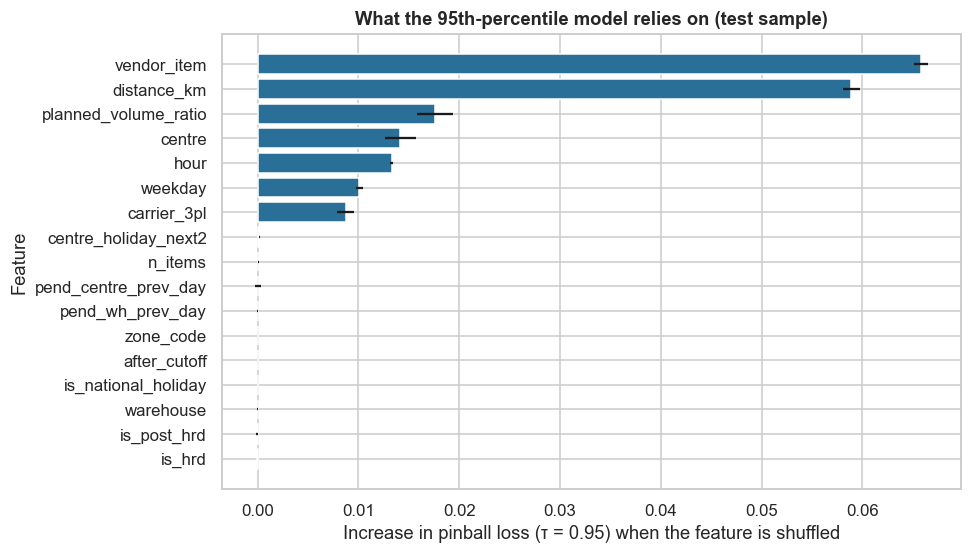

Top features: {'vendor_item': 0.0658, 'distance_km': 0.0589, 'planned_volume_ratio': 0.0176, 'centre': 0.0142, 'hour': 0.0133}


In [16]:
sub = TE.sample(6000, random_state=SEED); Xs, ys = sub[FEATS].values, sub.D.values
def pin_scorer(est, X, y): return -pin(y, est.predict(X)).mean()
pi = permutation_importance(m_q95, Xs, ys, scoring=pin_scorer, n_repeats=3, random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=FEATS).sort_values(); imp_sd = pd.Series(pi.importances_std, index=FEATS)[imp.index]
fig, ax = plt.subplots(figsize=(9, 5.2)); ax.barh(imp.index, imp.values, xerr=imp_sd.values, color="#2a6f97"); ax.set_xlabel("Increase in pinball loss (τ = 0.95) when the feature is shuffled"); ax.set_ylabel("Feature"); ax.set_title("What the 95th-percentile model relies on (test sample)")
plt.tight_layout(); plt.show(); print("Top features:", imp.sort_values(ascending=False).head(5).round(4).to_dict())

**Takeaway:** the model leans first on **whether the order has a vendor-procured item (permutation importance 0.066)** and **distance (0.059)**, then planned sale volume (0.018), the last-mile centre (0.014) and the hour of order (0.013). That matches the main sources of delay in the simulation and the linear model in 7.8. The previous-day backlog readings are not among the top five, partly because they are noisy. Operationally, vendor-procured items and sale-day volume are where the safe date moves most, so they are where a pendency alert is most valuable.

## 9. Business Translation — ₹ impact

Assumptions (D-5-08, all ours; the paper documents no revenue impact): **2 lakh orders a day**, average order value **₹1,300**, contribution margin **22%**. A later promise lowers conversion: **base 1% relative conversion per extra promised day** (worst 0.3%, best 2%). Each breach costs a support contact (₹40) and a chance of losing future margin: **base 6% churn × ₹900** (worst 3% × ₹600, best 8% × ₹1,200). The comparison is the best rule against the **rule-based table** on BAU test days: Δ mean promised days and Δ breach rate come from the BAU test results (the hybrid equals split-conformal on BAU days; sale days are covered in section 7). Extra orders from a shorter promise are modelled as orders × days saved × the elasticity (a first-order approximation).

#### Code

In [17]:
ORD, AOV, MG = 2e5, 1300, 0.22
scen = {"worst": (0.003, 0.03, 600), "base": (0.01, 0.06, 900), "best": (0.02, 0.08, 1200)}
r0 = score(PROM["1 rule-based (zone table)"], mb); out = {}
for k in ("2 mean + 1 day", "4 quantile regression (0.95)", "6 split-conformal", "7 Mondrian conformal (zone)", "8 rolling conformal (10-day)"):
    r = score(PROM[k], mb); dp = r0["mean_promise"] - r["mean_promise"]; db = r0["breach"] - r["breach"]; row = {"Δ promised days vs rule-based": dp, "Δ breach (pp)": db * 100}
    for sn, (el, ch, val) in scen.items():
        gain = ORD * dp * el * AOV * MG * 365 / 1e7; cost_save = ORD * db * (ch * val + 40) * 365 / 1e7; row[f"₹ crore/yr {sn}"] = gain + cost_save
    out[k] = row
bz = pd.DataFrame(out).T
sn_b = scen["base"]; cb = sn_b[1] * sn_b[2] + 40; cs_ = sn_b[0] * AOV * MG
print(f"Base case: a breach costs ₹{cb:,.0f}; a day of padding costs ₹{cs_:,.2f} per order in lost margin -> newsvendor-optimal quantile τ* = {cb / (cb + cs_):.3f} (breach {100 * (1 - cb / (cb + cs_)):.1f}%)")
for sn, (el, ch, val) in scen.items(): c1 = ch * val + 40; c2 = el * AOV * MG; print(f"  {sn}: breach ₹{c1:,.0f}, padding ₹{c2:,.2f} per order-day -> τ* = {c1 / (c1 + c2):.3f}")
msale = MASK["HRD (sale)"] | MASK["post-HRD"]; rs0 = score(PROM["1 rule-based (zone table)"], msale)
for k in ("4 quantile regression (0.95)", "6 split-conformal", "9 hybrid (conformal on BAU, plain QR on sale days)"):
    r = score(PROM[k], msale); print(f"Sale and post-sale days, {k}: promised days {r['mean_promise']:.2f} vs rule-based {rs0['mean_promise']:.2f}; breach {r['breach']:.1%} vs {rs0['breach']:.1%}; accuracy (0 to -2) {r['acc02']:.1%} vs {rs0['acc02']:.1%}")
bz.round(3)

Base case: a breach costs ₹94; a day of padding costs ₹2.86 per order in lost margin -> newsvendor-optimal quantile τ* = 0.970 (breach 3.0%)
  worst: breach ₹58, padding ₹0.86 per order-day -> τ* = 0.985
  base: breach ₹94, padding ₹2.86 per order-day -> τ* = 0.970
  best: breach ₹136, padding ₹5.72 per order-day -> τ* = 0.960
Sale and post-sale days, 4 quantile regression (0.95): promised days 5.76 vs rule-based 5.97; breach 4.5% vs 6.7%; accuracy (0 to -2) 73.5% vs 51.3%
Sale and post-sale days, 6 split-conformal: promised days 4.76 vs rule-based 5.97; breach 10.2% vs 6.7%; accuracy (0 to -2) 84.4% vs 51.3%
Sale and post-sale days, 9 hybrid (conformal on BAU, plain QR on sale days): promised days 5.76 vs rule-based 5.97; breach 4.5% vs 6.7%; accuracy (0 to -2) 73.5% vs 51.3%


,Δ promised days vs rule-based,Δ breach (pp),₹ crore/yr worst,₹ crore/yr base,₹ crore/yr best
2 mean + 1 day,0.9050,0.1050,6.1100,19.6100,38.8230
4 quantile regression (0.95),0.6770,0.7520,7.4240,19.2970,35.7400
6 split-conformal,1.6880,-2.8380,-1.4440,15.7640,42.3000
7 Mondrian conformal (zone),1.7320,-2.8630,-1.2750,16.5100,43.8860
8 rolling conformal (10-day),1.6100,-4.8740,-10.5510,0.1750,18.8510


**Takeaway (business reading):** versus the rule-based table on BAU days, **split-conformal shortens the promise by 1.69 days but raises the breach rate** from 2.0% to 4.9%. The net value is about **₹15.8 crore a year in the base case**, ₹-1.4 crore in the worst case and **₹42.3 crore** in the best case. Plain quantile regression shortens the promise by 0.68 days with 0.75 points fewer breaches and is worth ₹19.3 crore (worst ₹7.4 crore, best ₹35.7 crore), the better risk-adjusted choice on BAU days because it has the smaller downside; mean + 1 day is worth ₹19.6 crore (₹6.1 crore worst). Mondrian is worth ₹16.5 crore and rolling conformal about ₹0.2 crore (worst case ₹-10.6 crore). The newsvendor quantile is **τ* = 0.97 in the base case (0.985 worst, 0.96 best)**, above the 95% the business chose, meaning that if breaches cost what we assume, the 5% limit is not tight enough and the plain quantile model is not too cautious. On sale and post-sale days the hybrid promises 5.76 days against 5.97 for the table, with 4.5% breach against 6.7% and accuracy (0 to -2) of 73.5% against 51.3%; split-conformal would shorten the promise to 4.76 days but breach 10.2% of those orders. All rupee figures depend on assumed elasticities that have no documented source.

## 10. Recommendation and Decision

**Recommendation**

1. **Replace the rule-based table with a gradient-boosted 95th-percentile model** for the promised date, retrained daily on delivered orders.
2. **Calibrate with a split-conformal offset on normal days** (about -1.0 days on the rounded score scale in this data). It reaches 4.9% breach with 73.7% accuracy, against 2.0% and 16.6% for the table. If the business values breaches at the assumed ₹94 each, keep plain quantile regression (1.3% breach) instead.
3. **On sale and post-sale days use plain quantile regression with no offset** (4.6% and 4.3% breach in the test). A fixed conformal offset breaches 9.6% to 11.8% there.
4. **Do not use short-window feedback correction** while only a small share of recent orders is delivered (6.6% in a 3-day window).
5. **Monitor breach daily by zone and by cut-off timing**, with an alert at 6%, and certify by zone, not by lane (about 1,825 orders needed for ±1 point).
6. **Add an A/B test of the promise rule** to measure the real conversion effect of a shorter promise.

**Decision rule:** ship if BAU breach is at most 5% (day-level CI upper limit at most 6%), sale-day breach is at most 8%, and accuracy (0 to -1) is above the table's. Roll back a zone if its weekly breach exceeds 7%.

**Not yet known:** real conversion impact of a shorter promise, behaviour on real lanes and 3PL stalls, and whether the hybrid holds on a second sale event (it was chosen after seeing this one).

## 11. Risks, Limitations and Next Steps

- **Simulated network:** the sale-day effect, 3PL stalls and backlog dynamics were assumed. Real lanes will have different tails; re-run the calibration and the segment tests on real data before trusting any number here.
- **Delayed outcomes:** feedback and rolling calibration use only delivered orders, which biases them toward fast orders. In production use survival-style (censoring-aware) corrections or longer windows.
- **Exchangeability is the assumption:** conformal guarantees hold for the marginal distribution of the calibration days. Sale days, new couriers, weather and strikes break it; monitor breach by segment daily and recalibrate.
- **Promise changes behaviour:** a later date lowers conversion and an earlier one raises breach and cancellations; the elasticity here is an assumption and must come from an A/B test of promise rules (Case 19).
- **Integer days:** D is in whole days and the promise is a rounded-up quantile, so coverage is conservative; a time-of-day promise (Case 1) is the continuous version.
- **Scope:** a single total-time model; a leg-wise model (warehouse, vendor, shipping) would give a better pendency diagnosis for operations.

## 12. Appendix

| Quantity | Formula |
|---|---|
| Promise | P = ⌈ prediction ⌉ days after the order date |
| Breach | 1 if D > P |
| Accuracy (0 to −1) | 1 if P − 1 ≤ D ≤ P |
| Pinball loss (τ) | max(τ·(y − q), (τ − 1)·(y − q)) |
| Conformity score | s = D − 1 − q̂₀.₉₅(x) (D is an integer, so D > ⌈q̂ + c⌉ exactly when s ≥ c) |
| Split-conformal offset | the k-th smallest calibration score, k = ⌈(n+1)(1−α)⌉; promise ⌈q̂ + offset⌉ |
| Coverage law | Beta(k, n+1−k), mean k/(n+1) |
| Newsvendor quantile | τ* = C_breach / (C_breach + C_padding) |
| Design effect | 1 + (m − 1)·ICC |
| Sample size, CI | n = z²·p(1−p)/e² |

| Term | Meaning |
|---|---|
| Promise date | The delivery date shown at checkout |
| Breach | Delivery after the promised date |
| BAU / HRD | Business-as-usual day / high revenue (sale) day |
| Quantile regression | Fits a chosen percentile of the outcome instead of the mean |
| Conformal prediction | Calibrates a prediction so that it covers the outcome with a stated probability |
| Mondrian conformal | Conformal with a separate calibration per group |
| Pendency | Orders waiting in a warehouse, hub or last-mile centre |
| 3PL | Third-party logistics courier partner |
| Embargo | Days skipped between train and test while outcomes mature |